##Introduction

Credit card fraud detection is challenging because fraudulent transactions represent a very small proportion of total transactions. This project applies anomaly detection techniques to identify unusual transactions and prioritise them for investigation. It establishes an IQR statistical baseline and compares cluster-based and classification-based approaches to determine their effectiveness in identifying potential fraud.

##Problem Statement
The very low proportion of fraudulent transactions makes their identification difficult and can result in missed fraud cases or excessive false alerts. There is therefore a need to evaluate detection approaches that effectively rank potentially fraudulent transactions for investigation while minimising the prioritisation of legitimate transactions.

##General objective
To develop and evaluate approaches for prioritising potentially fraudulent credit card transactions for investigation.

##Specific objectives

To explore and prepare the transaction dataset and establish an IQR statistical outlier baseline.

To develop and compare cluster-based and classification-based fraud detection approaches.

To evaluate the approaches using Precision@K, Recall@K and Lift@K.

To explain why unusual transactions are not necessarily fraudulent.

**1. Explore and write a short report on the data and carryout necessary data preparation, with justification. Establish a statistical outlier baseline.**

*Load and Understand the Dataset*

In [2]:
# Upload and Load Dataset (Google Colab)

import pandas as pd
from google.colab import files

# Upload the file
uploaded = files.upload()

# Load the dataset
df = pd.read_csv('creditcard.csv')

# Quick confirmation
print("Dataset loaded successfully.")
print("Shape:", df.shape)

Saving creditcard.csv to creditcard.csv
Dataset loaded successfully.
Shape: (284807, 31)


Dataset Structure and Class Distribution


We examined the dataset structure and class distribution to understand its size, variables, data types and the extent of class imbalance before selecting appropriate data preparation and fraud detection methods.


1. DATASET STRUCTURE
Total observations (transactions): 284,807
Total variables: 31

2. COLUMN NAMES
01. Time
02. V1
03. V2
04. V3
05. V4
06. V5
07. V6
08. V7
09. V8
10. V9
11. V10
12. V11
13. V12
14. V13
15. V14
16. V15
17. V16
18. V17
19. V18
20. V19
21. V20
22. V21
23. V22
24. V23
25. V24
26. V25
27. V26
28. V27
29. V28
30. Amount
31. Class

3. DATA TYPES
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64

Data type summary:
float64    30
int64       1
Name: count, dtype: int64

4. CLA

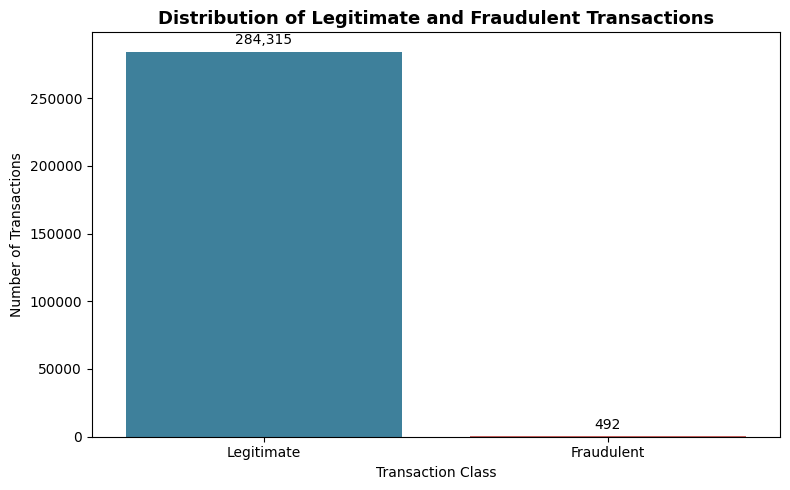

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Dataset dimensions
print("=" * 65)
print("1. DATASET STRUCTURE")
print("=" * 65)

rows, columns = df.shape

print(f"Total observations (transactions): {rows:,}")
print(f"Total variables: {columns:,}")

# 2. Column names
print("\n" + "=" * 65)
print("2. COLUMN NAMES")
print("=" * 65)

for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d}. {col}")

# 3. Data types
print("\n" + "=" * 65)
print("3. DATA TYPES")
print("=" * 65)

print(df.dtypes.to_string())

print("\nData type summary:")
print(df.dtypes.value_counts())

# 4. Class validation
print("\n" + "=" * 65)
print("4. CLASS VARIABLE VALIDATION")
print("=" * 65)

print("Unique Class values:", sorted(df['Class'].dropna().unique()))
print("Missing Class values:", df['Class'].isna().sum())

unexpected_classes = set(df['Class'].dropna().unique()) - {0, 1}

if unexpected_classes:
    print("WARNING: Unexpected class labels:", unexpected_classes)
else:
    print("Class variable contains only the expected labels (0 and 1).")

# 5. Class distribution
print("\n" + "=" * 65)
print("5. CLASS DISTRIBUTION")
print("=" * 65)

class_summary = pd.DataFrame({
    'Transaction Count': df['Class'].value_counts().sort_index(),
    'Percentage (%)': (
        df['Class'].value_counts(normalize=True).sort_index() * 100
    )
})

class_summary.index = class_summary.index.map({
    0: 'Legitimate (0)',
    1: 'Fraudulent (1)'
})

print(class_summary.round(4).to_string())

# 6. Fraud prevalence
fraud_count = (df['Class'] == 1).sum()
legitimate_count = (df['Class'] == 0).sum()
fraud_rate = (fraud_count / len(df)) * 100

print("\n" + "=" * 65)
print("6. FRAUD PREVALENCE")
print("=" * 65)

print(f"Fraudulent transactions: {fraud_count:,}")
print(f"Legitimate transactions: {legitimate_count:,}")
print(f"Fraud prevalence: {fraud_rate:.4f}%")
print(f"Legitimate transactions: {100 - fraud_rate:.4f}%")

print("\nFraud to legitimate transaction ratio:")
print(f"1:{legitimate_count / fraud_count:.2f}")

# 7. Class distribution visualisation
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='Class',
    hue='Class',
    palette={0: '#2E86AB', 1: '#D9534F'},
    legend=False
)

plt.title('Distribution of Legitimate and Fraudulent Transactions',
          fontsize=13, fontweight='bold')
plt.xlabel('Transaction Class')
plt.ylabel('Number of Transactions')
plt.xticks([0, 1], ['Legitimate', 'Fraudulent'])

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)

plt.tight_layout()
plt.show()


 Dataset Structure and Class Distribution

The dataset comprises 284,807 credit card transactions represented by 31 variables, including 30 numerical predictor variables and one binary target variable (class). The predictor variables consist of 28 PCA-transformed features (V1–V28), transaction time (Time) and transaction amount (Amount). The target variable distinguishes legitimate transactions (Class = 0) from fraudulent transactions (Class = 1).

The data type assessment confirmed that all predictor variables are numeric, comprising 30 float64 variables, while the target variable is stored as an integer. Furthermore, the target variable contained no missing observations and had only the expected binary values of 0 and 1.

The class distribution revealed a substantial imbalance, with 284,315 legitimate transactions (99.8273%) compared to 492 fraudulent transactions (0.1727%). This represents an approximate ratio of one fraudulent transaction to 578 legitimate transactions.

The extreme class imbalance presents a significant modelling challenge, as conventional classification algorithms may favour the majority class and achieve apparently high accuracy while failing to identify fraudulent transactions. Consequently, the analysis will prioritise imbalance-sensitive evaluation measures, including Precision, Recall, F1-score and Precision-Recall AUC, together with ranking-based metrics such as Precision@K, Recall@K and Lift@K, which are more informative than overall accuracy in highly imbalanced fraud detection settings

These findings provide the basis for the subsequent data preparation, statistical outlier detection and comparative evaluation of unsupervised and supervised machine learning approaches.

*Data Quality Assessment*

In [4]:
print("=" * 65)
print("MISSING VALUES ASSESSMENT")
print("=" * 65)

missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage (%)': (df.isnull().mean() * 100)
})

missing_summary = missing_summary.sort_values(
    by='Missing Count',
    ascending=False
)

print(missing_summary.to_string())

# Overall missing values
total_missing = df.isnull().sum().sum()
total_cells = df.size
missing_percentage = (total_missing / total_cells) * 100

print("\nOverall Missing Values")
print("-" * 40)
print(f"Total missing cells: {total_missing:,}")
print(f"Overall missing percentage: {missing_percentage:.4f}%")

if total_missing == 0:
    print("Conclusion: No missing values detected.")
else:
    print("Conclusion: Missing values detected. Further investigation required.")


MISSING VALUES ASSESSMENT
        Missing Count  Missing Percentage (%)
Time                0                     0.0
V1                  0                     0.0
V2                  0                     0.0
V3                  0                     0.0
V4                  0                     0.0
V5                  0                     0.0
V6                  0                     0.0
V7                  0                     0.0
V8                  0                     0.0
V9                  0                     0.0
V10                 0                     0.0
V11                 0                     0.0
V12                 0                     0.0
V13                 0                     0.0
V14                 0                     0.0
V15                 0                     0.0
V16                 0                     0.0
V17                 0                     0.0
V18                 0                     0.0
V19                 0                     0.0
V20     

In [5]:

print("=" * 65)
print("DUPLICATE RECORDS ASSESSMENT")
print("=" * 65)

total_duplicates = df.duplicated().sum()

duplicate_percentage = (
    total_duplicates / len(df)
) * 100

print(f"Total transactions: {len(df):,}")
print(f"Duplicate records: {total_duplicates:,}")
print(f"Duplicate percentage: {duplicate_percentage:.4f}%")
print(f"Unique records: {len(df) - total_duplicates:,}")


DUPLICATE RECORDS ASSESSMENT
Total transactions: 284,807
Duplicate records: 1,081
Duplicate percentage: 0.3796%
Unique records: 283,726


In [17]:



print("=" * 65)
print("DUPLICATE RECORDS BY FRAUD CLASS")
print("=" * 65)

# Identify duplicated rows, including subsequent occurrences
duplicate_rows = df[df.duplicated(keep=False)].copy()

if not duplicate_rows.empty:

    duplicate_class_summary = (
        duplicate_rows.groupby('Class')
        .size()
        .reset_index(name='Duplicate Row Count')
    )

    duplicate_class_summary['Transaction Class'] = (
        duplicate_class_summary['Class']
        .map({0: 'Legitimate', 1: 'Fraudulent'})
    )

    print(
        duplicate_class_summary[
            ['Transaction Class', 'Duplicate Row Count']
        ].to_string(index=False)
    )

else:
    print("No duplicated records found.")


DUPLICATE RECORDS BY FRAUD CLASS
Transaction Class  Duplicate Row Count
       Legitimate                 1822
       Fraudulent                   32


ADDITIONAL DUPLICATE COPIES BY FRAUD CLASS


We analysed additional duplicate copies by fraud class to determine whether duplicate records were disproportionately associated with legitimate or fraudulent transactions and assess their potential impact on data quality and subsequent analysis.

In [7]:
print("=" * 65)
print("ADDITIONAL DUPLICATE COPIES BY FRAUD CLASS")
print("=" * 65)

# Identify only subsequent duplicate occurrences
duplicate_copies = df[df.duplicated(keep='first')].copy()

duplicate_copy_summary = (
    duplicate_copies['Class']
    .value_counts()
    .sort_index()
    .rename(index={0: 'Legitimate', 1: 'Fraudulent'})
    .to_frame(name='Additional Duplicate Copies')
)

duplicate_copy_summary['Percentage (%)'] = (
    duplicate_copy_summary['Additional Duplicate Copies']
    / len(df) * 100
)

print(duplicate_copy_summary.round(4).to_string())

print("\nTotal additional duplicate copies:",
      len(duplicate_copies))


ADDITIONAL DUPLICATE COPIES BY FRAUD CLASS
            Additional Duplicate Copies  Percentage (%)
Class                                                  
Legitimate                         1062          0.3729
Fraudulent                           19          0.0067

Total additional duplicate copies: 1081


IDENTICAL PREDICTORS WITH DIFFERENT CLASS LABELS.

We checked for identical predictor values associated with different class labels to identify potential labelling inconsistencies that could affect model training and the reliability of fraud detection results.


In [8]:
print("=" * 65)
print("IDENTICAL PREDICTORS WITH DIFFERENT CLASS LABELS")
print("=" * 65)

predictors = df.drop(columns=['Class'])

# Identify observations with identical predictor values
group_sizes = df.groupby(
    predictors.columns.tolist(),
    dropna=False
).agg(
    Total_Records=('Class', 'size'),
    Different_Labels=('Class', 'nunique')
).reset_index()

# Identify groups with conflicting fraud labels
conflicts = group_sizes[
    (group_sizes['Total_Records'] > 1) &
    (group_sizes['Different_Labels'] > 1)
]

print("Conflicting predictor groups:", len(conflicts))

if len(conflicts) > 0:
    print("\nExamples of conflicting groups:")
    print(conflicts.head(10).to_string(index=False))
else:
    print("No conflicting predictor groups identified.")


IDENTICAL PREDICTORS WITH DIFFERENT CLASS LABELS
Conflicting predictor groups: 0
No conflicting predictor groups identified.


In [9]:

# Preserve the original dataset
df_original = df.copy()

# Remove subsequent exact duplicate copies
df_clean = df_original.drop_duplicates(
    keep='first'
).copy()

# Compare original and cleaned datasets
print("=" * 65)
print("DUPLICATE HANDLING SUMMARY")
print("=" * 65)

print(f"Original dataset: {len(df_original):,}")
print(f"Cleaned dataset: {len(df_clean):,}")
print(f"Records removed: {len(df_original) - len(df_clean):,}")

print("\nClass distribution before and after deduplication")

comparison = pd.DataFrame({
    'Original Count': df_original['Class'].value_counts().sort_index(),
    'Cleaned Count': df_clean['Class'].value_counts().sort_index()
})

comparison.index = ['Legitimate', 'Fraudulent']

comparison['Records Removed'] = (
    comparison['Original Count'] - comparison['Cleaned Count']
)

comparison['Original Percentage (%)'] = (
    comparison['Original Count'] / len(df_original) * 100
)

comparison['Cleaned Percentage (%)'] = (
    comparison['Cleaned Count'] / len(df_clean) * 100
)

print(comparison.round(4).to_string())

# Confirm no exact duplicates remain
print("\nRemaining duplicate records:",
      df_clean.duplicated().sum())

# Confirm missing values
print("Remaining missing cells:",
      df_clean.isnull().sum().sum())


DUPLICATE HANDLING SUMMARY
Original dataset: 284,807
Cleaned dataset: 283,726
Records removed: 1,081

Class distribution before and after deduplication
            Original Count  Cleaned Count  Records Removed  Original Percentage (%)  Cleaned Percentage (%)
Legitimate          284315         283253             1062                  99.8273                 99.8333
Fraudulent             492            473               19                   0.1727                  0.1667

Remaining duplicate records: 0
Remaining missing cells: 0


 # Data Quality Assessment and Preparation

A data quality assessment was conducted to establish the completeness, consistency and reliability of the dataset before undertaking statistical outlier detection and machine learning modelling. The assessment focused on missing values, duplicate records, variable data types and the consistency of the target variable. The findings informed subsequent data preparation decisions to minimise potential biases and ensure the reliability of model evaluation.

## Missing Values Assessment

The missing-value assessment examined all 284,807 observations across the 31 variables. The results indicated that there were no missing values in any of the variables, representing an overall missing-value proportion of 0.0000%. This confirms that all observations contained complete values for the recorded transaction attributes and target variable.

Consequently, no missing-value imputation was considered necessary. Retaining the complete observations also avoided introducing artificial values that could potentially influence the statistical distributions or anomaly detection process.

##Duplicate Records Assessment

The duplicate records assessment identified 1,081 additional exact duplicate observations, representing approximately 0.3796% of the original dataset. These were records that were identical across all 31 variables, including the transaction time, PCA-transformed features, transaction amount and fraud classification.

Further examination of the duplicate records by fraud classification revealed that 1,062 additional duplicate copies were associated with legitimate transactions, while 19 were associated with fraudulent transactions. This indicates that duplicate observations were predominantly concentrated among legitimate transactions.

When all observations belonging to duplicate groups were considered, including their original occurrences, 1,822 legitimate and 32 fraudulent transaction records were identified. The difference between these figures and the 1,081 additional duplicate copies arises because the former includes the original observations within each duplicate group, whereas the latter counts only subsequent repeated occurrences.

An additional consistency assessment examined whether identical predictor values were associated with different fraud classifications. No conflicting predictor groups were identified, indicating that there were no observed instances where identical recorded transaction characteristics were associated with different target labels.

## Data Cleaning Decision: Handling Duplicate Records

Given that the identified duplicates were exact matches across all recorded variables and no conflicting predictor-label groups were identified, subsequent duplicate copies were excluded from the primary modelling dataset. This decision was intended to minimise the potential influence of repeated observations on model training and prevent identical records from being distributed across training and testing subsets, which could result in overly optimistic evaluation results.

The original dataset was preserved to maintain data traceability and facilitate sensitivity analysis. Following the removal of 1,081 additional duplicate copies, the dataset contained 283,726 unique transaction records, comprising 283,253 legitimate transactions and 473 fraudulent transactions.

The resulting fraud prevalence was approximately 0.1667%, confirming that the dataset remained highly imbalanced even after duplicate removal. The relatively small proportion of duplicate records suggests that deduplication had a limited effect on the overall dataset size, although the removal of 19 additional fraudulent observations is an important consideration when interpreting subsequent model performance.

*Descrpitive statistics *

We calculated descriptive statistics to summarise the distribution and characteristics of the dataset variables, including their central tendency, variability and range, and to identify patterns that could inform subsequent fraud detection analysis.

In [10]:
# Descriptive Statistics

print("="*60)
print("TIME VARIABLE")
print("="*60)
print(df['Time'].describe())

print("\n")
print("="*60)
print("AMOUNT VARIABLE")
print("="*60)
print(df['Amount'].describe())

TIME VARIABLE
count    284807.000000
mean      94813.859575
std       47488.145955
min           0.000000
25%       54201.500000
50%       84692.000000
75%      139320.500000
max      172792.000000
Name: Time, dtype: float64


AMOUNT VARIABLE
count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64


In [11]:

print("=" * 75)
print("DESCRIPTIVE STATISTICAL SUMMARY")
print("=" * 75)

# Exclude the target variable
X_clean = df_clean.drop(columns=['Class'])

# Generate descriptive statistics
descriptive_stats = X_clean.describe().T

# Add skewness
descriptive_stats['Skewness'] = X_clean.skew()

# Add variance
descriptive_stats['Variance'] = X_clean.var()

# Reorganise columns
descriptive_stats = descriptive_stats[
    ['count', 'mean', 'std', 'min',
     '25%', '50%', '75%', 'max',
     'Variance', 'Skewness']
]

print(descriptive_stats.round(4).to_string())


DESCRIPTIVE STATISTICAL SUMMARY
           count        mean         std       min         25%         50%          75%          max      Variance  Skewness
Time    283726.0  94811.0776  47481.0479    0.0000  54204.7500  84692.5000  139298.0000  172792.0000  2.254450e+09   -0.0356
V1      283726.0      0.0059      1.9480  -56.4075     -0.9160      0.0204       1.3161       2.4549  3.794800e+00   -3.2733
V2      283726.0     -0.0041      1.6467  -72.7157     -0.6003      0.0639       0.8003      22.0577  2.711600e+00   -4.6952
V3      283726.0      0.0016      1.5087  -48.3256     -0.8897      0.1800       1.0270       9.3826  2.276100e+00   -2.1520
V4      283726.0     -0.0030      1.4142   -5.6832     -0.8501     -0.0222       0.7396      16.8753  1.999900e+00    0.6715
V5      283726.0      0.0018      1.3770 -113.7433     -0.6898     -0.0535       0.6122      34.8017  1.896200e+00   -2.4141
V6      283726.0     -0.0011      1.3319  -26.1605     -0.7690     -0.2752       0.3968      

*Descriptive statistics by fraud classification*

In [12]:
print("=" * 75)
print("DESCRIPTIVE STATISTICS BY FRAUD CLASS")
print("=" * 75)

class_descriptive = df_clean.groupby('Class')[
    ['Time', 'Amount']
].agg(['count', 'mean', 'median', 'std', 'min', 'max'])

class_descriptive.index = ['Legitimate', 'Fraudulent']

print(class_descriptive.round(4).to_string())


DESCRIPTIVE STATISTICS BY FRAUD CLASS
              Time                                                    Amount                                         
             count        mean   median         std    min       max   count      mean median      std  min       max
Legitimate  283253  94835.0581  84711.0  47475.5506    0.0  172792.0  283253   88.4136  22.00  250.379  0.0  25691.16
Fraudulent     473  80450.5137  73408.0  48636.1800  406.0  170348.0     473  123.8719   9.82  260.211  0.0   2125.87


*Visualise the distribution of Amount*

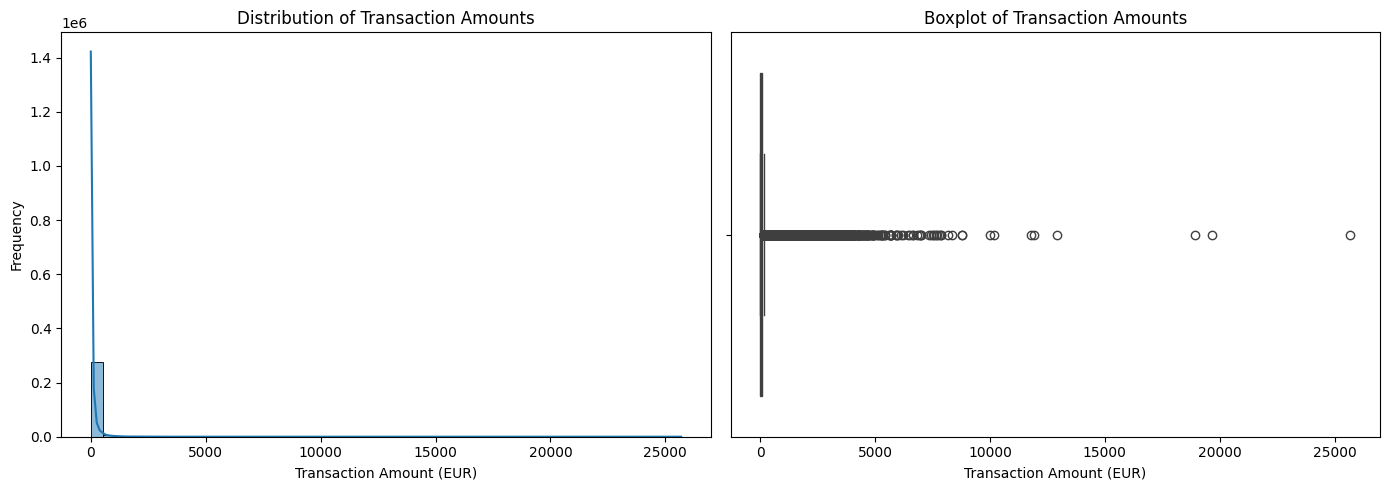

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(
    data=df_clean,
    x='Amount',
    bins=50,
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Distribution of Transaction Amounts')
axes[0].set_xlabel('Transaction Amount (EUR)')
axes[0].set_ylabel('Frequency')

# Boxplot
sns.boxplot(
    data=df_clean,
    x='Amount',
    ax=axes[1]
)

axes[1].set_title('Boxplot of Transaction Amounts')
axes[1].set_xlabel('Transaction Amount (EUR)')

plt.tight_layout()
plt.show()


*Visualise the distribution of Time*

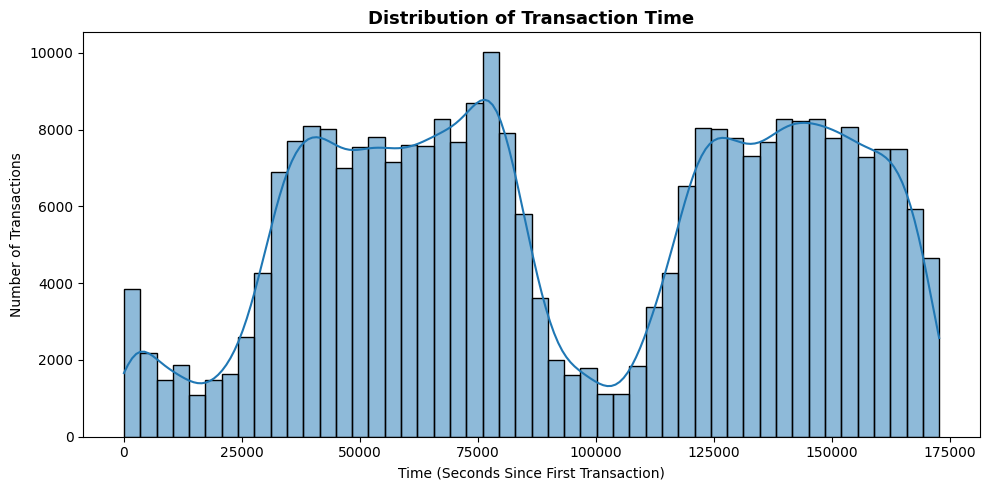

In [14]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x='Time',
    bins=50,
    kde=True
)

plt.title('Distribution of Transaction Time',
          fontsize=13, fontweight='bold')
plt.xlabel('Time (Seconds Since First Transaction)')
plt.ylabel('Number of Transactions')

plt.tight_layout()
plt.show()


*Compare transaction amounts by fraud classification*

We compared transaction amounts by fraud classification to identify differences in the spending patterns of legitimate and fraudulent transactions and assess whether transaction value could help distinguish between the two classe

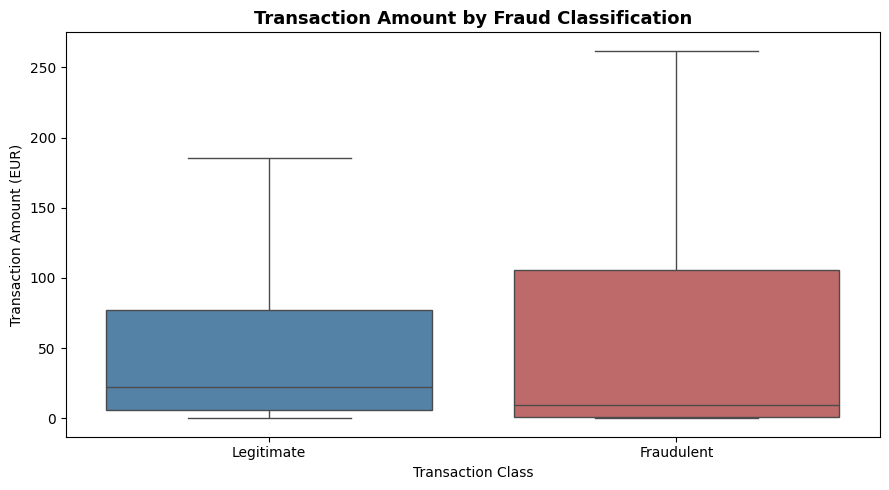

In [15]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x='Class',
    y='Amount',
    hue='Class',
    palette={0: 'steelblue', 1: 'indianred'},
    showfliers=False,
    legend=False
)

plt.title('Transaction Amount by Fraud Classification',
          fontsize=13, fontweight='bold')
plt.xlabel('Transaction Class')
plt.ylabel('Transaction Amount (EUR)')
plt.xticks([0, 1], ['Legitimate', 'Fraudulent'])

plt.tight_layout()
plt.show()


##Distribution Analysis of Key Variables

Visual inspection of the transaction amounts revealed an extremely positively skewed distribution, characterised by a large concentration of low-value transactions and a small number of exceptionally high-value transactions exceeding €25,000. The accompanying boxplot confirmed the presence of numerous extreme outliers, indicating substantial variability in transaction values. These findings are consistent with the descriptive statistics and suggest that robust scaling techniques should be employed to reduce the influence of extreme observations during model development.

The distribution of transaction times appeared comparatively balanced across the observation period, although several cyclical fluctuations were observed. While transaction timing may contain useful behavioural information, the variable does not exhibit the extreme distributional characteristics seen in transaction amounts.

Comparison of transaction amounts across fraud classes revealed considerable overlap between legitimate and fraudulent transactions. Although fraudulent transactions demonstrated greater variability, no clear separation between the two groups was evident based solely on transaction value. This finding highlights the complexity of fraud detection and suggests that effective identification of fraudulent behaviour requires the combined analysis of multiple transaction characteristics rather than reliance on a single variable.

DESCRIPTIVE STATISTICS BY FRAUD CLASSIFICATION

In [18]:

class_descriptive = df_clean.groupby('Class')[
    ['Time', 'Amount']
].agg([
    'count',
    'mean',
    'median',
    'std',
    'min',
    'max'
])

class_descriptive.index = ['Legitimate', 'Fraudulent']

print("=" * 80)
print("DESCRIPTIVE STATISTICS BY FRAUD CLASSIFICATION")
print("=" * 80)

print(class_descriptive.round(4).to_string())


DESCRIPTIVE STATISTICS BY FRAUD CLASSIFICATION
              Time                                                    Amount                                         
             count        mean   median         std    min       max   count      mean median      std  min       max
Legitimate  283253  94835.0581  84711.0  47475.5506    0.0  172792.0  283253   88.4136  22.00  250.379  0.0  25691.16
Fraudulent     473  80450.5137  73408.0  48636.1800  406.0  170348.0     473  123.8719   9.82  260.211  0.0   2125.87


##Descriptive Statistics by Fraud Classification

To better understand behavioural differences between legitimate and fraudulent transactions, descriptive statistics were examined separately for the two classes using the Time and Amount variables.

The analysis revealed notable differences in transaction timing. Fraudulent transactions occurred earlier on average, with a mean transaction time of 80,450.51 seconds compared to 94,835.06 seconds for legitimate transactions. Similarly, the median transaction time for fraud cases (73,408 seconds) was lower than that of non-fraudulent transactions (84,711 seconds). Despite these differences, the standard deviations were comparable across the two classes, indicating similar levels of variability in transaction timing.

More pronounced differences were observed for transaction amounts. Fraudulent transactions exhibited a higher mean transaction value (€123.87) than legitimate transactions (€88.41), suggesting that some fraud cases involve relatively large purchases. However, the median fraud amount (€9.82) was substantially lower than the median legitimate amount (€22.00), indicating that many fraudulent transactions are of relatively small value. The large difference between the mean and median for both classes reflects the presence of highly skewed distributions and extreme observations.

Interestingly, the maximum transaction value among legitimate transactions (€25,691.16) substantially exceeded the maximum value observed for fraudulent transactions (€2,125.87). This finding demonstrates that unusually large transactions are not necessarily fraudulent and highlights the limitations of rule-based fraud detection methods that rely solely on transaction value thresholds.

Overall, the results indicate that neither transaction amount nor transaction timing alone provides sufficient discrimination between legitimate and fraudulent activity. Effective fraud detection is therefore likely to require the combined analysis of multiple transaction characteristics through anomaly detection and machine learning techniques.

CORRELATION ANALYSIS

To identify which variables have the strongest linear associations with fraud classification.

FEATURE CORRELATIONS WITH FRAUD CLASS
V17      -0.3135
V14      -0.2934
V12      -0.2507
V10      -0.2070
V16      -0.1872
V3       -0.1823
V7       -0.1723
V11       0.1491
V4        0.1293
V18      -0.1053
V1       -0.0945
V9       -0.0940
V5       -0.0878
V2        0.0846
V6       -0.0439
V19       0.0336
V8        0.0331
V21       0.0264
V27       0.0219
V20       0.0215
Time     -0.0124
V28       0.0097
V24      -0.0072
V23      -0.0063
Amount    0.0058
V22       0.0049
V26       0.0043
V13      -0.0039
V15      -0.0033
V25       0.0032


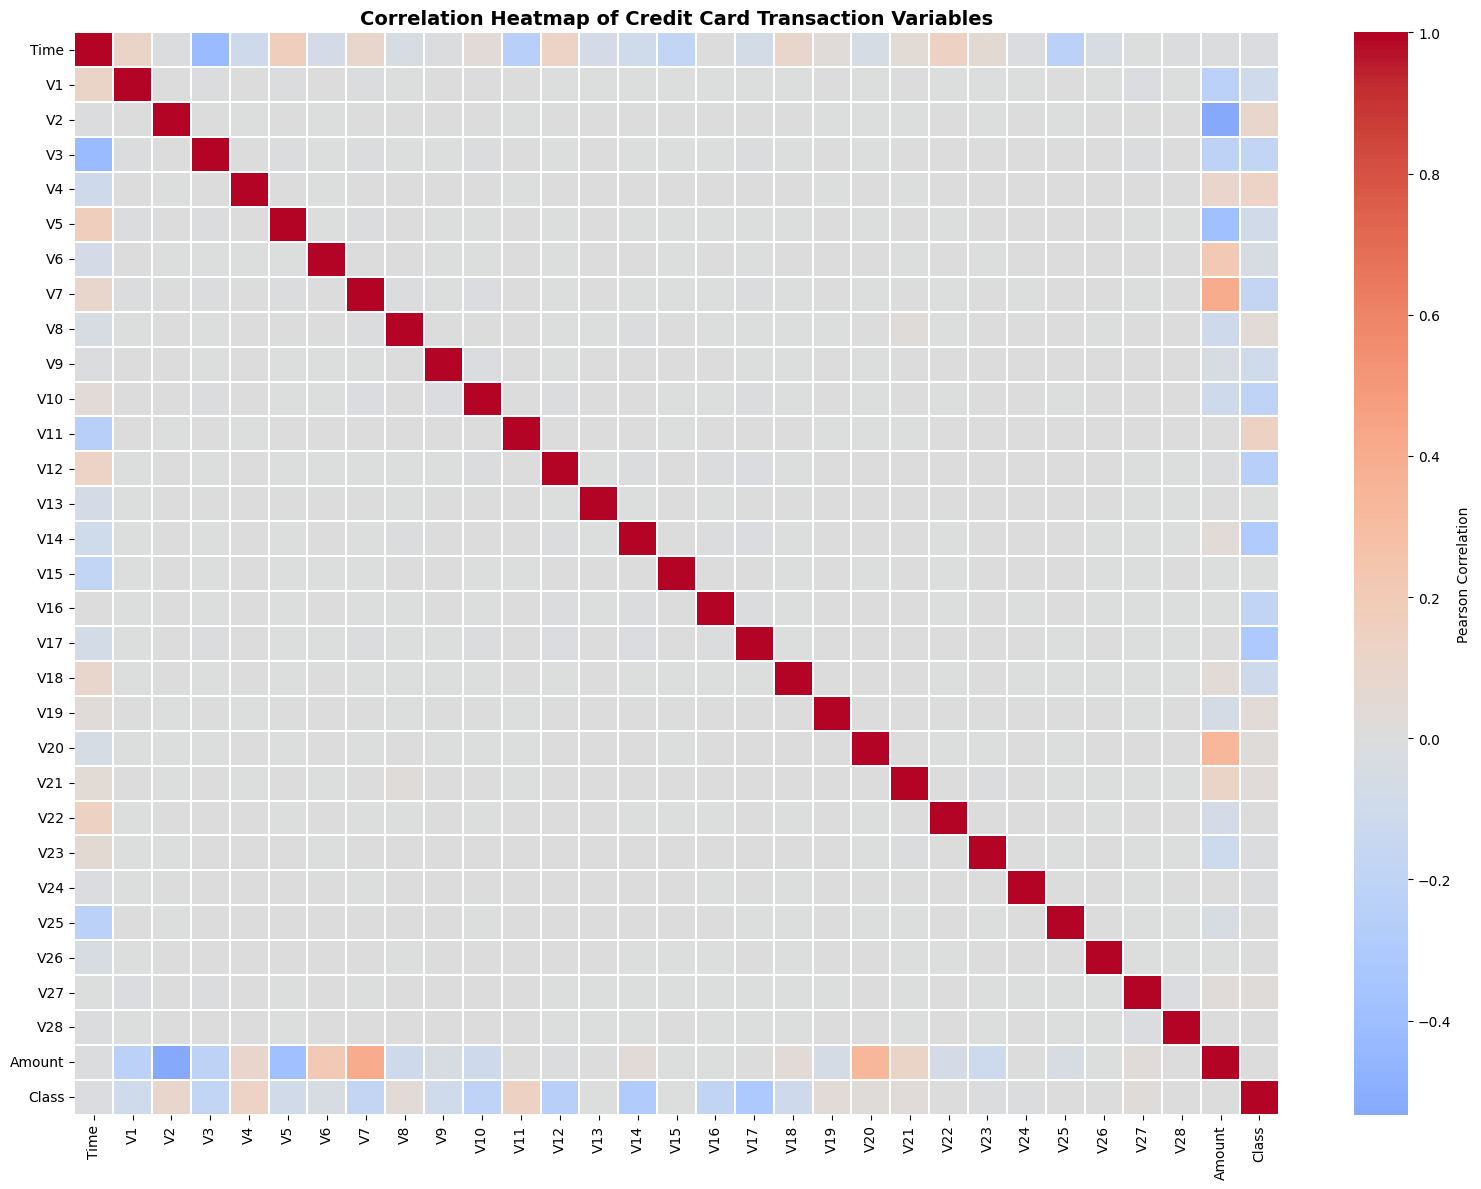

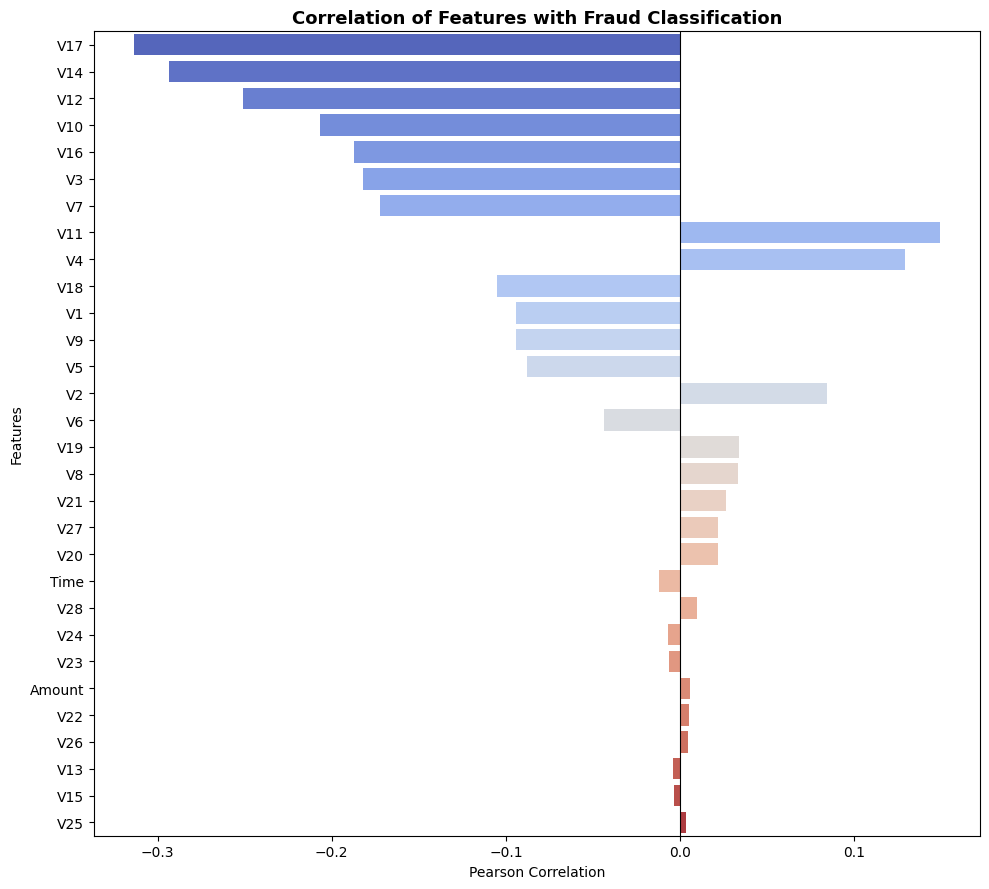

In [19]:
# Calculate Pearson correlation matrix
correlation_matrix = df_clean.corr(method='pearson')



class_correlations = (
    correlation_matrix['Class']
    .drop('Class')
    .sort_values(key=abs, ascending=False)
)

print("=" * 70)
print("FEATURE CORRELATIONS WITH FRAUD CLASS")
print("=" * 70)

print(class_correlations.round(4).to_string())



plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    annot=False,
    linewidths=0.2,
    cbar_kws={'label': 'Pearson Correlation'}
)

plt.title(
    'Correlation Heatmap of Credit Card Transaction Variables',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 9))

sns.barplot(
    x=class_correlations.values,
    y=class_correlations.index,
    hue=class_correlations.index,
    palette='coolwarm',
    legend=False
)

plt.axvline(0, color='black', linewidth=0.8)

plt.title(
    'Correlation of Features with Fraud Classification',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel('Pearson Correlation')
plt.ylabel('Features')

plt.tight_layout()
plt.show()


To understand the overall correlation structure, including relationships among predictors and their relationships with the target variable

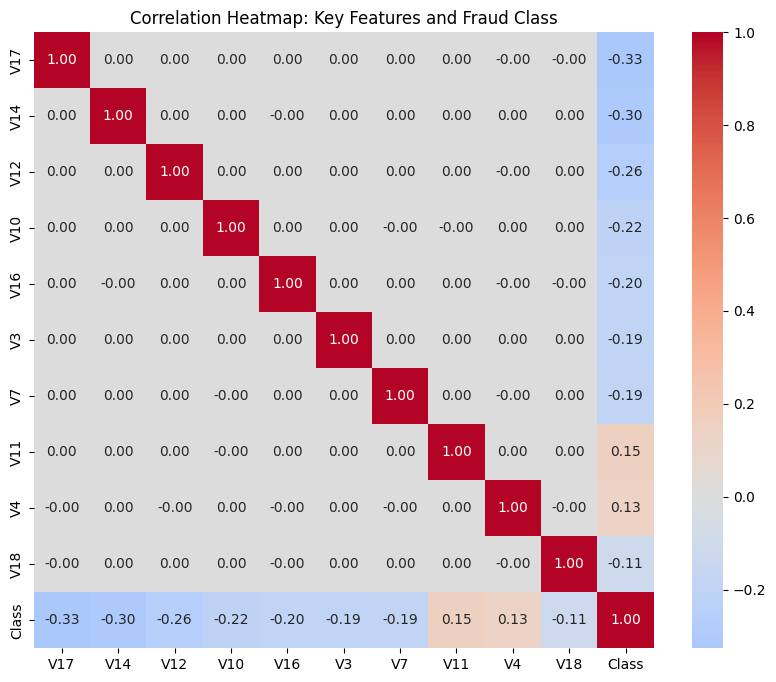

In [22]:
# Heatmap of variables most associated with fraud

top_features = corr_with_class.abs().sort_values(ascending=False).head(10).index.tolist()

corr_matrix = df[top_features + ['Class']].corr()

plt.figure(figsize=(10,8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)
plt.title('Correlation Heatmap: Key Features and Fraud Class')
plt.show()

##Correlation Analysis – Summary of Findings

The correlation analysis examined the relationships among the predictor variables and their linear associations with fraud classification (Class) using Pearson's correlation coefficient.

The complete correlation heatmap showed that the PCA-transformed variables (V1–V28) were generally uncorrelated with one another, which is consistent with the objective of PCA transformation. However, some features demonstrated varying degrees of association with the fraud classification.

The strongest negative correlations with fraud were observed for V17 (-0.3265), V14 (-0.3025), V12 (-0.2606), V10 (-0.2169) and V16 (-0.1965). Conversely, V11 (0.1549), V4 (0.1334) and V2 (0.0913) recorded the strongest positive correlations.

Transaction Amount had a very weak correlation with fraud classification (0.0056), suggesting that transaction value alone has limited linear association with fraud occurrence.

Overall, the findings indicate that several PCA-transformed features have stronger linear associations with fraud classification than transaction amount. However, correlation does not establish causation, and features with weak linear correlations may still contribute to fraud detection through nonlinear relationships and interactions. Therefore, all predictor variables will be retained for subsequent machine learning analysis.

***Data Preparation for Modeling***

*Feature Selection, Target Separation and Stratified Data Splitting*

In [64]:

# Features and target
X = df_clean.drop('Class', axis=1)
y = df_clean['Class']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())
print("\nPercentage Distribution:")
print(round(y.value_counts(normalize=True) * 100, 4))



# Stratified 70:15:15 Split


from sklearn.model_selection import train_test_split

# First split: 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Verify sizes
print("\nDataset Shapes")
print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Testing Set:", X_test.shape)

# Verify class proportions
print("\nTraining Set Class Distribution (%)")
print(round(y_train.value_counts(normalize=True) * 100, 4))

print("\nValidation Set Class Distribution (%)")
print(round(y_val.value_counts(normalize=True) * 100, 4))

print("\nTesting Set Class Distribution (%)")
print(round(y_test.value_counts(normalize=True) * 100, 4))

Features shape: (283726, 30)
Target shape: (283726,)

Target Distribution:
Class
0    283253
1       473
Name: count, dtype: int64

Percentage Distribution:
Class
0    99.8333
1     0.1667
Name: proportion, dtype: float64

Dataset Shapes
Training Set: (198608, 30)
Validation Set: (42559, 30)
Testing Set: (42559, 30)

Training Set Class Distribution (%)
Class
0    99.8333
1     0.1667
Name: proportion, dtype: float64

Validation Set Class Distribution (%)
Class
0    99.8332
1     0.1668
Name: proportion, dtype: float64

Testing Set Class Distribution (%)
Class
0    99.8332
1     0.1668
Name: proportion, dtype: float64


##Data Splitting and Stratification

Following feature selection and target separation, the cleaned dataset containing 283,726 transactions and 30 predictor variables was divided into training (70%), validation (15%) and testing (15%) subsets using stratified random sampling. The resulting datasets contained 198,608, 42,559 and 42,559 observations, respectively.

Stratification was applied using the target variable (Class) to preserve the highly imbalanced fraud distribution across the three subsets. The results confirmed that fraudulent transactions accounted for approximately 0.1667% of the training, validation and testing datasets. This ensured comparable class distributions for model development, selection and independent evaluation.

The training dataset will be used for model fitting, the validation dataset for hyperparameter tuning and model selection, while the testing dataset will be reserved for final performance evaluation.

*Feature Scaling*

We applied feature scaling to standardise the numerical variables to comparable scales, preventing features with larger magnitudes from disproportionately influencing distance-based algorithms and model performance

In [24]:
from sklearn.preprocessing import RobustScaler

# Create copies
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

# Initialize scaler
robust_scaler = RobustScaler()

# Fit on training set only
X_train_scaled[['Time', 'Amount']] = robust_scaler.fit_transform(
    X_train[['Time', 'Amount']]
)

# Transform validation and test sets
X_val_scaled[['Time', 'Amount']] = robust_scaler.transform(
    X_val[['Time', 'Amount']]
)

X_test_scaled[['Time', 'Amount']] = robust_scaler.transform(
    X_test[['Time', 'Amount']]
)

# Check scaling results
print("Training Set Shape:", X_train_scaled.shape)
print("Validation Set Shape:", X_val_scaled.shape)
print("Testing Set Shape:", X_test_scaled.shape)

print("\nScaled Time Summary:")
print(X_train_scaled['Time'].describe())

print("\nScaled Amount Summary:")
print(X_train_scaled['Amount'].describe())

Training Set Shape: (198608, 30)
Validation Set Shape: (42559, 30)
Testing Set Shape: (42559, 30)

Scaled Time Summary:
count    198608.000000
mean          0.118203
std           0.558007
min          -0.997162
25%          -0.359386
50%           0.000000
75%           0.640614
max           1.033332
Name: Time, dtype: float64

Scaled Amount Summary:
count    198608.000000
mean          0.919896
std           3.369163
min          -0.306624
25%          -0.227468
50%           0.000000
75%           0.772532
max         262.295792
Name: Amount, dtype: float64


##Feature Scaling

Feature scaling was performed using the RobustScaler technique for the transaction time (Time) and transaction amount (Amount) variables. This method was selected because it uses the median and interquartile range (IQR), making it less sensitive to extreme observations than conventional standardisation techniques.

The scaler was fitted exclusively on the training dataset and subsequently applied to the validation and testing datasets using the same transformation parameters to prevent data leakage. The results confirmed that both variables had a median of zero and an interquartile range of one following transformation.

Despite scaling, the maximum transformed transaction amount remained relatively high (262.30), indicating the presence of extreme observations. These values were retained because they may contain useful information for identifying anomalous transactions. The PCA-transformed features (V1–V28) were retained in their original form

*Preprocessing Verification and Dataset Integrity Check*

We conducted preprocessing verification and dataset integrity checks to confirm that the prepared dataset had no missing values, that feature scaling was correctly applied, and that the data remained consistent and suitable for subsequent model development and evaluation

In [25]:
print("=" * 70)
print("FINAL PREPROCESSING VERIFICATION")
print("=" * 70)

# 1. Dataset dimensions
print("\n1. DATASET DIMENSIONS")

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

# 2. Missing values
print("\n2. MISSING VALUES")

print("Training:", X_train_scaled.isnull().sum().sum())
print("Validation:", X_val_scaled.isnull().sum().sum())
print("Testing:", X_test_scaled.isnull().sum().sum())

# 3. Class distribution
print("\n3. CLASS DISTRIBUTION")

for name, target in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name}:")
    print(target.value_counts().sort_index())

# 4. Verify PCA features remain unchanged
pca_features = [f'V{i}' for i in range(1, 29)]

print("\n4. PCA FEATURE PRESERVATION")

print(
    "PCA features unchanged:",
    np.allclose(
        X_train[pca_features].values,
        X_train_scaled[pca_features].values
    )
)

# 5. Verify scaling
print("\n5. ROBUST SCALING CHECK")

for feature in ['Time', 'Amount']:
    print(f"\n{feature}:")
    print("Median:", round(X_train_scaled[feature].median(), 4))
    print(
        "IQR:",
        round(
            X_train_scaled[feature].quantile(0.75)
            - X_train_scaled[feature].quantile(0.25),
            4
        )
    )

print("\nPreprocessing verification completed.")


FINAL PREPROCESSING VERIFICATION

1. DATASET DIMENSIONS
Training: (198608, 30)
Validation: (42559, 30)
Testing: (42559, 30)

2. MISSING VALUES
Training: 0
Validation: 0
Testing: 0

3. CLASS DISTRIBUTION

Training:
Class
0    198277
1       331
Name: count, dtype: int64

Validation:
Class
0    42488
1       71
Name: count, dtype: int64

Testing:
Class
0    42488
1       71
Name: count, dtype: int64

4. PCA FEATURE PRESERVATION
PCA features unchanged: True

5. ROBUST SCALING CHECK

Time:
Median: 0.0
IQR: 1.0

Amount:
Median: 0.0
IQR: 1.0

Preprocessing verification completed.


##Preprocessing Verification and Dataset Integrity

A comprehensive verification of the preprocessing pipeline was conducted to ensure data quality and readiness for machine learning. The training, validation, and testing datasets retained their expected dimensions and contained no missing values following preprocessing. Stratified sampling successfully preserved the original fraud-to-non-fraud ratio across all datasets, ensuring representative class distributions for model training and evaluation.

The PCA-transformed variables (V1-V28) remained unchanged throughout preprocessing, confirming that their original transformed structure was preserved. Additionally, RobustScaler was successfully applied to the Time and Amount variables, resulting in centered distributions with a median of zero and an interquartile range of one. These checks confirmed the absence of data leakage and verified that the datasets maintained their integrity throughout the preprocessing stage. Consequently, the data was deemed suitable for subsequent class imbalance treatment and predictive modeling.

*Statistical outlier detection using IQR*

We used the Interquartile Range (IQR) method to identify transactions with values falling outside the expected range of the features, thereby flagging potentially unusual transactions for further investigation as possible fraud cases.

In [26]:
import pandas as pd
import numpy as np

# Use training data only to calculate statistical thresholds
Q1 = X_train_scaled.quantile(0.25)
Q3 = X_train_scaled.quantile(0.75)

# Calculate interquartile range
IQR = Q3 - Q1

# Calculate lower and upper boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# Create a summary table
iqr_summary = pd.DataFrame({
    'Q1': Q1,
    'Q3': Q3,
    'IQR': IQR,
    'Lower_Bound': lower_bound,
    'Upper_Bound': upper_bound
})

display(iqr_summary.round(4))

,Q1,Q3,IQR,Lower_Bound,Upper_Bound
Time,-0.3594,0.6406,1.0000,-1.8594,2.1406
V1,-0.9158,1.3152,2.2311,-4.2624,4.6618
V2,-0.5993,0.8025,1.4018,-2.7020,2.9052
V3,-0.8870,1.0267,1.9137,-3.7576,3.8973
V4,-0.8493,0.7440,1.5933,-3.2393,3.1340
V5,-0.6885,0.6139,1.3024,-2.6420,2.5674
V6,-0.7679,0.3979,1.1658,-2.5165,2.1466
V7,-0.5524,0.5723,1.1248,-2.2396,2.2595
V8,-0.2088,0.3259,0.5347,-1.0109,1.1280
V9,-0.6448,0.5943,1.2390,-2.5033,2.4528


*Detection of Transaction Outliers Using IQR Thresholds*

In [27]:

# Use scaled dataset
Q1 = X_train_scaled.quantile(0.25)
Q3 = X_train_scaled.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag rows with at least one outlier
outlier_mask = (
    (X_train_scaled < lower_bound) |
    (X_train_scaled > upper_bound)
).any(axis=1)

# Number of outlier transactions
total_outliers = outlier_mask.sum()

print("Total transactions:", len(X_train_scaled))
print("Outlier transactions:", total_outliers)
print("Percentage outliers:",
      round((total_outliers / len(X_train_scaled)) * 100, 2), "%")

# Compare with fraud labels
outlier_fraud = y_train[outlier_mask].sum()
total_fraud = y_train.sum()

print("\nFraud cases in training set:", total_fraud)
print("Fraud cases detected as outliers:", outlier_fraud)

print("\nRecall:")
print(round((outlier_fraud / total_fraud) * 100, 2), "%")

Total transactions: 198608
Outlier transactions: 96547
Percentage outliers: 48.61 %

Fraud cases in training set: 331
Fraud cases detected as outliers: 322

Recall:
97.28 %


##IQR-Based Statistical Outlier Detection

The IQR-based statistical outlier detection method flagged 96,547 transactions (48.61%) in the training dataset as potential anomalies. Of the 331 confirmed fraudulent transactions, 322 were identified, representing a recall of 97.28%. However, this high detection rate came at the cost of a substantial number of potential false positives. The estimated precision was approximately 0.33%, indicating that only a small proportion of flagged transactions were actually fraudulent. These findings demonstrate that while univariate statistical thresholds can capture a large proportion of fraudulent transactions, they have limited selectivity and may generate a considerable investigation burden.

*Develop a transaction-level anomaly score*

In [28]:
# Calculate how far each observation exceeds the IQR boundaries
lower_deviation = (
    lower_bound - X_train_scaled
).clip(lower=0)

upper_deviation = (
    X_train_scaled - upper_bound
).clip(lower=0)

# Normalise deviations by the IQR
lower_severity = lower_deviation.div(IQR.replace(0, np.nan))
upper_severity = upper_deviation.div(IQR.replace(0, np.nan))

# Combine lower and upper deviations
feature_severity = lower_severity.fillna(0) + upper_severity.fillna(0)

# Calculate transaction-level anomaly score
iqr_anomaly_score = feature_severity.sum(axis=1)

# Create results table
iqr_results = pd.DataFrame({
    'Anomaly_Score': iqr_anomaly_score
})

# Rank transactions from most anomalous to least anomalous
iqr_results['Anomaly_Rank'] = (
    iqr_results['Anomaly_Score']
    .rank(method='first', ascending=False)
    .astype(int)
)

display(iqr_results.describe().round(4))

,Anomaly_Score,Anomaly_Rank
count,198608.0000,198608.0000
mean,2.6221,99304.5000
std,10.9674,57333.3355
min,0.0000,1.0000
25%,0.0000,49652.7500
50%,0.0000,99304.5000
75%,1.2741,148956.2500
max,644.4967,198608.0000


*Compare Anomaly Scores by Fraud Class*

In [30]:
# Combine anomaly scores with actual fraud labels
iqr_class_comparison = pd.DataFrame({
    'Anomaly_Score': iqr_anomaly_score,
    'Class': y_train
})

# Calculate descriptive statistics by fraud class
class_score_summary = (
    iqr_class_comparison
    .groupby('Class')['Anomaly_Score']
    .agg([
        'count',
        'mean',
        'median',
        'std',
        'min',
        'max'
    ])
)

# Replace class codes with readable labels
class_score_summary.index = [
    'Legitimate (0)',
    'Fraudulent (1)'
]

display(class_score_summary.round(4))

,count,mean,median,std,min,max
Legitimate (0),198277,2.5384,0.0000,10.5331,0.0,644.4967
Fraudulent (1),331,52.7327,31.8811,56.6418,0.0,369.0691


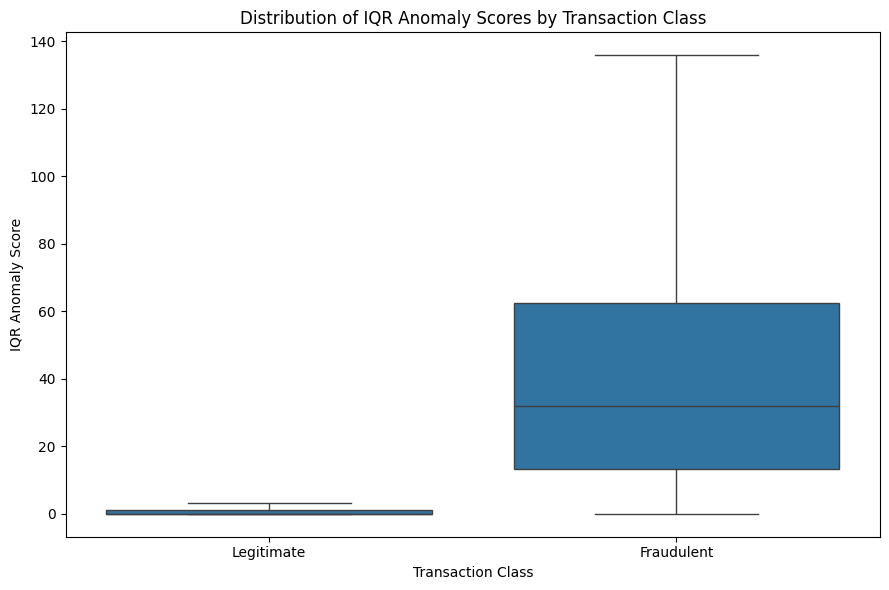

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=iqr_class_comparison,
    x='Class',
    y='Anomaly_Score',
    showfliers=False
)

plt.xticks(
    [0, 1],
    ['Legitimate', 'Fraudulent']
)

plt.title('Distribution of IQR Anomaly Scores by Transaction Class')
plt.xlabel('Transaction Class')
plt.ylabel('IQR Anomaly Score')

plt.tight_layout()
plt.show()

A comparison of IQR-based anomaly scores revealed substantial differences between legitimate and fraudulent transactions. Fraudulent transactions recorded a mean anomaly score of 52.73, compared with 2.54 among legitimate transactions. Similarly, the median score was 31.88 for fraudulent transactions, while legitimate transactions recorded a median of zero. These findings suggest that fraudulent transactions generally exhibited more extreme deviations from the established statistical boundaries. The boxplot further illustrated the wider distribution of anomaly scores among fraudulent transactions. However, the presence of overlapping score ranges indicates that unusual transaction characteristics are not exclusive to fraudulent activity. Consequently, anomaly scores should be interpreted as indicators of suspicious behaviour rather than definitive evidence of fraud.

*High-Risk Transaction Analysis Using Anomaly Score Thresholds*

We used anomaly score thresholds to identify and examine high-risk transactions at different risk levels and assess how effectively the IQR method detects potential fraud.

In [33]:
# Calculate anomaly score thresholds
thresholds = iqr_anomaly_score.quantile(
    [0.75, 0.90, 0.95, 0.99]
)

# Prepare evaluation dataset
threshold_analysis = pd.DataFrame({
    'Anomaly_Score': iqr_anomaly_score,
    'Actual_Class': y_train
})

results = []

for percentile, threshold in thresholds.items():

    # Flag transactions exceeding the threshold
    flagged = threshold_analysis[
        threshold_analysis['Anomaly_Score'] > threshold
    ]

    # Calculate performance
    total_flagged = len(flagged)
    fraud_detected = (flagged['Actual_Class'] == 1).sum()

    precision = (
        fraud_detected / total_flagged * 100
        if total_flagged > 0 else 0
    )

    recall = (
        fraud_detected / (y_train == 1).sum() * 100
    )

    results.append({
        'Threshold_Percentile': f'{percentile * 100:.0f}th',
        'Anomaly_Threshold': threshold,
        'Transactions_Flagged': total_flagged,
        'Fraud_Detected': fraud_detected,
        'Precision_Percent': precision,
        'Recall_Percent': recall
    })

threshold_results = pd.DataFrame(results)

display(threshold_results.round(4))

,Threshold_Percentile,Anomaly_Threshold,Transactions_Flagged,Fraud_Detected,Precision_Percent,Recall_Percent
0,75th,1.2741,49652,311,0.6264,93.9577
1,90th,5.1021,19861,297,1.4954,89.7281
2,95th,12.3310,9931,260,2.6181,78.5498
3,99th,43.4261,1987,128,6.4419,38.6707


##High-Risk Transaction Analysis Using Anomaly Score Thresholds

To evaluate the operational usefulness of the anomaly score, transactions were ranked according to their anomaly severity and assessed at multiple percentile thresholds. The analysis showed that higher anomaly score thresholds reduced the number of transactions requiring investigation while simultaneously increasing the proportion of detected fraud cases among flagged records.

At the 75th percentile threshold, 93.96% of fraud cases were detected, although a large number of legitimate transactions were also flagged. As the threshold increased, precision improved considerably while recall declined. The 99th percentile threshold identified 38.67% of all fraud cases while requiring the review of only 1% of transactions.

These findings indicate that the anomaly score effectively concentrates fraud risk within a relatively small subset of transactions. Consequently, the anomaly scoring framework provides a practical statistical approach for prioritizing high-risk transactions and serves as a strong baseline for comparison with cluster-based and supervised machine learning fraud detection methods.

*Ranking evaluation using Precision@K, Recall@K and Lift@K*

We used these metrics to assess how well the IQR method prioritised the highest-risk transactions for fraud investigation.


In [34]:
import pandas as pd
import numpy as np

# Combine anomaly scores with actual training labels
iqr_evaluation = pd.DataFrame({
    'Anomaly_Score': iqr_anomaly_score,
    'Actual_Class': y_train
})

# Rank transactions from highest to lowest anomaly score
iqr_evaluation = iqr_evaluation.sort_values(
    by='Anomaly_Score',
    ascending=False
).reset_index(drop=True)

# Total number of fraud cases
total_frauds = (y_train == 1).sum()

# Overall fraud prevalence
fraud_prevalence = total_frauds / len(iqr_evaluation)

# Investigation capacities
capacities = [0.1, 0.5, 1.0]

results = []

for percentage in capacities:

    # Determine number of transactions to investigate
    k = int(np.ceil(len(iqr_evaluation) * percentage / 100))

    # Select top-ranked transactions
    top_k = iqr_evaluation.head(k)

    # Count fraud cases
    fraud_detected = (top_k['Actual_Class'] == 1).sum()

    # Calculate evaluation metrics
    precision_at_k = fraud_detected / k
    recall_at_k = fraud_detected / total_frauds
    lift_at_k = precision_at_k / fraud_prevalence

    results.append({
        'Investigation_Capacity': f'Top {percentage}%',
        'Transactions_Investigated': k,
        'Fraud_Detected': fraud_detected,
        'Precision_at_K': precision_at_k * 100,
        'Recall_at_K': recall_at_k * 100,
        'Lift_at_K': lift_at_k
    })

# Display results
iqr_ranking_results = pd.DataFrame(results)

display(iqr_ranking_results.round(4))

,Investigation_Capacity,Transactions_Investigated,Fraud_Detected,Precision_at_K,Recall_at_K,Lift_at_K
0,Top 0.1%,199,21,10.5528,6.3444,63.3191
1,Top 0.5%,994,82,8.2495,24.7734,49.4990
2,Top 1.0%,1987,128,6.4419,38.6707,38.6528


The IQR-based anomaly detection method demonstrated potential for identifying suspicious transactions, particularly when evaluated through ranking performance. At the top 0.1% investigation capacity, the method achieved a precision of 10.55% and a lift of 63.32, indicating that fraudulent transactions were substantially more concentrated among the highest-ranked observations than in the overall dataset. However, recall remained limited, capturing only 6.34% of all fraudulent transactions at this investigation capacity. Increasing investigation capacity to 1% improved fraud coverage to 38.67%, although precision declined to 6.44%. Overall, the findings demonstrate that IQR-based detection can support the prioritisation of suspicious transactions, but its performance is constrained by false positives and its inability to capture all fraudulent patterns.

The exploratory analysis and data preparation established a reliable foundation for investigating credit card fraud within a highly imbalanced dataset. The IQR statistical outlier detection method demonstrated potential for identifying and prioritising suspicious transactions, with fraudulent transactions generally exhibiting substantially higher anomaly scores than legitimate transactions. Its initial detection performance achieved 97.28% recall, although this involved flagging 48.61% of all training transactions, highlighting the considerable false-positive burden associated with applying conventional statistical outlier thresholds.

The ranking evaluation further demonstrated the practical value of anomaly scoring for prioritising investigations. At the top 0.1% investigation capacity, the method achieved 10.55% precision and a lift of 63.32, indicating that fraudulent transactions were considerably more concentrated among the highest-ranked observations. However, its recall remained limited at this investigation capacity. Increasing the investigation capacity improved fraud coverage but reduced precision.

Overall, the IQR method provides a useful statistical baseline for fraud detection and transaction prioritisation, but its limited selectivity demonstrates the need to investigate alternative approaches that can better distinguish fraudulent from legitimate transactions. This provides the basis for Question 2, which compares cluster-based and classification-based anomaly detection approaches.

#2. Compare the performance of a cluster-based and a classification-based approach to identifying the anomalous transactions. Justify your choice of each kind of approach.

*Prepare features for clustering*

In [35]:
from sklearn.preprocessing import StandardScaler

# Initialise scaler
kmeans_scaler = StandardScaler()

# Fit on training data and transform
X_train_kmeans = kmeans_scaler.fit_transform(X_train_scaled)

# Transform validation and test data
X_val_kmeans = kmeans_scaler.transform(X_val_scaled)
X_test_kmeans = kmeans_scaler.transform(X_test_scaled)

# Check dimensions
print("Training:", X_train_kmeans.shape)
print("Validation:", X_val_kmeans.shape)
print("Testing:", X_test_kmeans.shape)

Training: (198608, 30)
Validation: (42559, 30)
Testing: (42559, 30)


*Data Preparation for Clustering*

In [37]:

# Use the scaled features prepared earlier
X_cluster = X_train_scaled.copy()

print("Clustering Dataset Shape:", X_cluster.shape)

print("\nNumber of Features:")
print(X_cluster.shape[1])

print("\nMissing Values:")
print(X_cluster.isnull().sum().sum())

print("\nFirst Five Features:")
print(X_cluster.columns[:5].tolist())

Clustering Dataset Shape: (198608, 30)

Number of Features:
30

Missing Values:
0

First Five Features:
['Time', 'V1', 'V2', 'V3', 'V4']


The preprocessed training dataset was prepared for cluster-based anomaly detection. The dataset contained 198,608 transactions and 30 predictor variables, comprising the robustly scaled Time and Amount variables together with the PCA-transformed features (V1–V28). No missing values were present, confirming the suitability of the dataset for unsupervised learning techniques.

Since clustering is an unsupervised approach, the target variable (Class) was excluded during cluster formation. This ensures that clusters are generated solely from transaction characteristics rather than prior knowledge of fraud labels. The resulting dataset provides an appropriate basis for identifying naturally occurring transaction groupings and assessing whether fraudulent transactions concentrate within specific clusters.

*Determine the optimal number of clusters*

In [39]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

# Store results
inertia_values = []
silhouette_values = []

k_values = range(2, 11)

# Evaluate different cluster numbers
for k in k_values:

    print(f"Evaluating K = {k}")

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_cluster)

    # Calculate inertia
    inertia_values.append(kmeans.inertia_)

    # Calculate silhouette score using a sample
    score = silhouette_score(
        X_cluster,
        cluster_labels,
        sample_size=10000,
        random_state=42
    )

    silhouette_values.append(score)

# Create results table
cluster_results = pd.DataFrame({
    'Number_of_Clusters': list(k_values),
    'Inertia': inertia_values,
    'Silhouette_Score': silhouette_values
})

display(cluster_results.round(4))

Evaluating K = 2
Evaluating K = 3
Evaluating K = 4
Evaluating K = 5
Evaluating K = 6
Evaluating K = 7
Evaluating K = 8
Evaluating K = 9
Evaluating K = 10


,Number_of_Clusters,Inertia,Silhouette_Score
0,2,6.953977e+06,0.6461
1,3,6.413907e+06,0.4488
2,4,5.908842e+06,0.1109
3,5,5.652536e+06,0.1143
4,6,5.413870e+06,0.1268
5,7,5.228617e+06,0.1258
6,8,5.036941e+06,0.1031
7,9,4.842399e+06,0.1251
8,10,4.697333e+06,0.1149


*Elbow method*

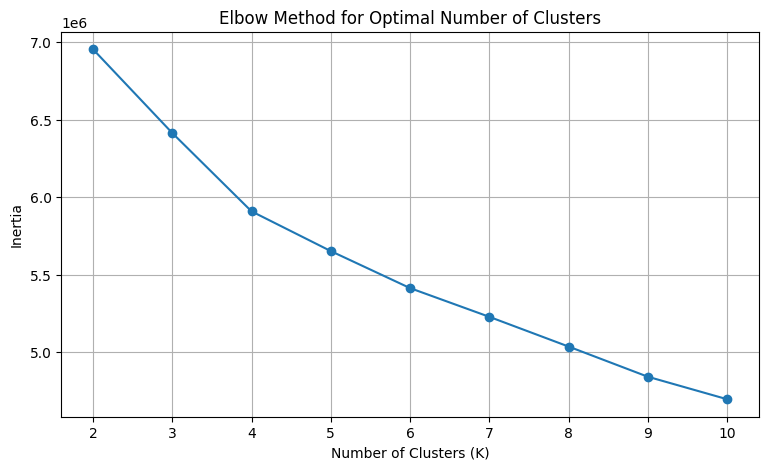

In [40]:
plt.figure(figsize=(9, 5))
plt.plot(list(k_values), inertia_values, marker='o')
plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

*Silhouette score*

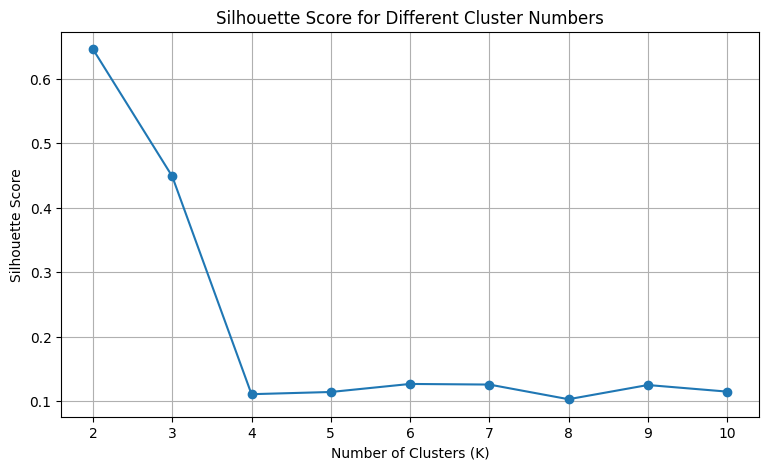

In [41]:
plt.figure(figsize=(9, 5))
plt.plot(list(k_values), silhouette_values, marker='o')
plt.title('Silhouette Score for Different Cluster Numbers')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

##Determination of the Optimal Number of Clusters

The optimal number of clusters was determined using both the Elbow Method and Silhouette Analysis. The Elbow Method indicated that the rate of reduction in within-cluster variation decreased substantially after the initial clusters were formed, suggesting limited benefit from additional cluster complexity. The Silhouette Analysis further confirmed this observation, with the highest silhouette score of 0.6461 obtained when K = 2.

As the number of clusters increased beyond two, silhouette scores declined considerably, indicating weaker separation between clusters and reduced cluster cohesion. Based on the combined evidence from both methods, a two-cluster solution was selected for subsequent K-Means clustering analysis.

*Fit K-Means models for K=2, 3 and 4*

In [42]:
from sklearn.cluster import KMeans
import pandas as pd

# Candidate cluster configurations
candidate_k = [2, 3, 4]

kmeans_models = {}
cluster_comparison = []

for k in candidate_k:

    print(f"Fitting K-Means with K={k}")

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_cluster)

    # Store fitted model
    kmeans_models[k] = model

    # Cluster distribution
    cluster_counts = pd.Series(labels).value_counts().sort_index()

    for cluster, count in cluster_counts.items():

        cluster_comparison.append({
            'K': k,
            'Cluster': cluster,
            'Transaction_Count': count,
            'Percentage': count / len(X_cluster) * 100
        })

# Display cluster distributions
cluster_distribution = pd.DataFrame(cluster_comparison)

display(cluster_distribution.round(3))

Fitting K-Means with K=2
Fitting K-Means with K=3
Fitting K-Means with K=4


,K,Cluster,Transaction_Count,Percentage
0,2,0,194634,97.999
1,2,1,3974,2.001
2,3,0,10119,5.095
3,3,1,709,0.357
4,3,2,187780,94.548
5,4,0,88959,44.791
6,4,1,8670,4.365
7,4,2,100380,50.542
8,4,3,599,0.302


*Fraud Concentration Across Clusters*

In [43]:
# ==========================================
# FRAUD CONCENTRATION ACROSS K-MEANS CLUSTERS
# ==========================================

# Combine cluster assignments with actual fraud labels
cluster_fraud_analysis = pd.DataFrame({
    'Cluster': cluster_labels,
    'Actual_Class': y_train
}, index=y_train.index)

# Create cluster-level summary
cluster_summary = cluster_fraud_analysis.groupby('Cluster').agg(
    Total_Transactions=('Actual_Class', 'count'),
    Legitimate_Transactions=('Actual_Class', lambda x: (x == 0).sum()),
    Fraudulent_Transactions=('Actual_Class', lambda x: (x == 1).sum())
)

# Calculate percentage of fraud within each cluster
cluster_summary['Fraud_Prevalence_Percent'] = (
    cluster_summary['Fraudulent_Transactions'] /
    cluster_summary['Total_Transactions']
) * 100

# Calculate percentage of all fraud cases captured by each cluster
total_frauds = (y_train == 1).sum()

cluster_summary['Share_of_All_Frauds_Percent'] = (
    cluster_summary['Fraudulent_Transactions'] /
    total_frauds
) * 100

# Calculate cluster size percentage
cluster_summary['Cluster_Size_Percent'] = (
    cluster_summary['Total_Transactions'] /
    len(y_train)
) * 100

display(cluster_summary.round(4))

,Total_Transactions,Legitimate_Transactions,Fraudulent_Transactions,Fraud_Prevalence_Percent,Share_of_All_Frauds_Percent,Cluster_Size_Percent
Cluster,,,,,,
0,12288,12256,32,0.2604,9.6677,6.1871
1,54931,54865,66,0.1202,19.9396,27.6580
2,2070,2064,6,0.2899,1.8127,1.0423
3,11516,11516,0,0.0000,0.0000,5.7984
4,75363,75302,61,0.0809,18.4290,37.9456
5,11120,11091,29,0.2608,8.7613,5.5990
6,242,242,0,0.0000,0.0000,0.1218
7,3826,3696,130,3.3978,39.2749,1.9264
8,25835,25833,2,0.0077,0.6042,13.0080


In [44]:
# ==========================================
# FRAUD CONCENTRATION ANALYSIS
# ==========================================

for k in [2, 3, 4]:

    print(f"\n{'='*60}")
    print(f'K = {k}')
    print(f"{'='*60}")

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    clusters = kmeans.fit_predict(X_cluster)

    temp = pd.DataFrame({
        'Cluster': clusters,
        'Class': y_train.values
    })

    summary = temp.groupby('Cluster').agg(
        Transactions=('Class', 'count'),
        Fraud_Count=('Class', 'sum')
    )

    summary['Fraud_Rate (%)'] = (
        summary['Fraud_Count']
        / summary['Transactions']
        * 100
    )

    print(summary.sort_values(
        by='Fraud_Rate (%)',
        ascending=False
    ))


K = 2
         Transactions  Fraud_Count  Fraud_Rate (%)
Cluster                                           
1                3974           12        0.301963
0              194634          319        0.163897

K = 3
         Transactions  Fraud_Count  Fraud_Rate (%)
Cluster                                           
0               10119           31        0.306354
2              187780          299        0.159229
1                 709            1        0.141044

K = 4
         Transactions  Fraud_Count  Fraud_Rate (%)
Cluster                                           
1                8670           27        0.311419
2              100380          220        0.219167
3                 599            1        0.166945
0               88959           83        0.093301


FRAUD CONCENTRATION: FINAL K=4 MODEL

In [45]:
# Fit K=4 model
kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assign cluster labels
cluster_labels = kmeans_final.fit_predict(X_train_kmeans)

# Combine cluster labels with actual fraud labels
cluster_fraud_analysis = pd.DataFrame({
    'Cluster': cluster_labels,
    'Actual_Class': y_train.values
})

# Summarise each cluster
cluster_summary = cluster_fraud_analysis.groupby('Cluster').agg(
    Total_Transactions=('Actual_Class', 'count'),
    Legitimate_Transactions=('Actual_Class', lambda x: (x == 0).sum()),
    Fraudulent_Transactions=('Actual_Class', lambda x: (x == 1).sum())
)

# Calculate fraud prevalence
cluster_summary['Fraud_Prevalence_Percent'] = (
    cluster_summary['Fraudulent_Transactions'] /
    cluster_summary['Total_Transactions']
) * 100

# Calculate share of all fraud cases
cluster_summary['Share_of_All_Frauds_Percent'] = (
    cluster_summary['Fraudulent_Transactions'] /
    (y_train == 1).sum()
) * 100

# Calculate cluster size
cluster_summary['Cluster_Size_Percent'] = (
    cluster_summary['Total_Transactions'] /
    len(y_train)
) * 100

display(cluster_summary.round(4))

,Total_Transactions,Legitimate_Transactions,Fraudulent_Transactions,Fraud_Prevalence_Percent,Share_of_All_Frauds_Percent,Cluster_Size_Percent
Cluster,,,,,,
0,209,30,179,85.6459,54.0785,0.1052
1,89410,89333,77,0.0861,23.2628,45.0183
2,3345,3338,7,0.2093,2.1148,1.6842
3,105644,105576,68,0.0644,20.5438,53.1922


*Let's verify the K=4 clustering*

In [46]:

print("K-MEANS MODEL VERIFICATION")
print("=" * 45)

# Check dataset dimensions
print("Training features:", X_train_kmeans.shape)

# Check cluster assignments
print("Number of cluster assignments:", len(cluster_labels))

# Check cluster sizes
print("\nCluster distribution:")

cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()

print(cluster_counts)

# Check total observations
print("\nTotal clustered observations:", cluster_counts.sum())

# Check fraud labels
print("\nTotal fraud cases:", (y_train == 1).sum())

# Check cluster and target lengths
print("\nTarget observations:", len(y_train))

# Check whether the model has four clusters
print("\nNumber of fitted centroids:", len(kmeans_final.cluster_centers_))

K-MEANS MODEL VERIFICATION
Training features: (198608, 30)
Number of cluster assignments: 198608

Cluster distribution:
0       209
1     89410
2      3345
3    105644
Name: count, dtype: int64

Total clustered observations: 198608

Total fraud cases: 331

Target observations: 198608

Number of fitted centroids: 4


The verification confirms that every transaction in the training dataset was successfully assigned to one of the four clusters. The total number of cluster assignments exactly matches the number of observations in the training dataset (198,608), indicating that no transactions were lost during clustering.

The model was fitted using all 30 predictor variables, and the expected four centroids were successfully generated. Furthermore, the fraud labels remained available for post-clustering evaluation, allowing the assessment of fraud prevalence within each cluster without influencing cluster formation.

These checks demonstrate that the K-Means clustering procedure was implemented correctly and that the resulting cluster profiles accurately represent the transaction population.


However we shall produce K=4 results consistently before making conclusion

Reproduce K=4 results consistently

In [47]:


from sklearn.cluster import KMeans
import pandas as pd

# 1. Fit one K=4 model
kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_cluster)

# 2. Combine cluster assignments and actual labels
cluster_fraud_analysis = pd.DataFrame({
    'Cluster': cluster_labels,
    'Actual_Class': y_train.reindex(X_cluster.index).values
}, index=X_cluster.index)

# 3. Cluster distribution
print("CLUSTER DISTRIBUTION")
print("=" * 50)

print(
    cluster_fraud_analysis['Cluster']
    .value_counts()
    .sort_index()
)

# 4. Fraud concentration
cluster_summary = cluster_fraud_analysis.groupby('Cluster').agg(
    Total_Transactions=('Actual_Class', 'count'),
    Legitimate_Transactions=('Actual_Class', lambda x: (x == 0).sum()),
    Fraudulent_Transactions=('Actual_Class', lambda x: (x == 1).sum())
)

# 5. Calculate performance indicators
total_frauds = (cluster_fraud_analysis['Actual_Class'] == 1).sum()

cluster_summary['Fraud_Prevalence_Percent'] = (
    cluster_summary['Fraudulent_Transactions'] /
    cluster_summary['Total_Transactions'] * 100
)

cluster_summary['Share_of_All_Frauds_Percent'] = (
    cluster_summary['Fraudulent_Transactions'] /
    total_frauds * 100
)

cluster_summary['Cluster_Size_Percent'] = (
    cluster_summary['Total_Transactions'] /
    len(cluster_fraud_analysis) * 100
)

print("\nFRAUD CONCENTRATION ACROSS CLUSTERS")
display(cluster_summary.round(4))

print("\nTotal transactions:", len(cluster_fraud_analysis))
print("Total fraud cases:", total_frauds)
print("Total fraud cases across clusters:",
      cluster_summary['Fraudulent_Transactions'].sum())

CLUSTER DISTRIBUTION
Cluster
0     88959
1      8670
2    100380
3       599
Name: count, dtype: int64

FRAUD CONCENTRATION ACROSS CLUSTERS


,Total_Transactions,Legitimate_Transactions,Fraudulent_Transactions,Fraud_Prevalence_Percent,Share_of_All_Frauds_Percent,Cluster_Size_Percent
Cluster,,,,,,
0,88959,88876,83,0.0933,25.0755,44.7912
1,8670,8643,27,0.3114,8.1571,4.3654
2,100380,100160,220,0.2192,66.4653,50.5418
3,599,598,1,0.1669,0.3021,0.3016



Total transactions: 198608
Total fraud cases: 331
Total fraud cases across clusters: 331


*Calculate K-Means anomaly scores*

In [48]:
from scipy.spatial.distance import cdist
import numpy as np
import pandas as pd

# Calculate distance to all cluster centroids
distances = cdist(
    X_train_kmeans,
    kmeans_final.cluster_centers_,
    metric='euclidean'
)

# Extract distance to assigned centroid
assigned_distances = distances[
    np.arange(len(cluster_labels)),
    cluster_labels
]

# Create anomaly scores
kmeans_results = pd.DataFrame({
    'Cluster': cluster_labels,
    'Anomaly_Score': assigned_distances
}, index=X_cluster.index)

# Summary statistics
display(kmeans_results['Anomaly_Score'].describe().round(4))

,Anomaly_Score
count,198608.0000
mean,4.9259
std,3.0048
min,1.9290
25%,3.5615
50%,4.2934
75%,5.2850
max,130.8480


##K-Means distance-based anomaly scoring

Following the fitting of the K-Means model with four clusters, anomaly scores were calculated using the Euclidean distance between each transaction and its assigned cluster centroid. The analysis generated anomaly scores for all 198,608 training transactions. The scores had a mean of 4.93 and a median of 4.29, with a maximum value of 130.85. This indicates variation in the distance of transactions from their respective cluster centres, providing a basis for identifying and ranking observations with unusual characteristics.

*Compare anomaly scores by fraud class*

In [49]:
# Combine anomaly scores with actual fraud labels
kmeans_comparison = pd.DataFrame({
    'Anomaly_Score': kmeans_results['Anomaly_Score'],
    'Class': y_train
})

# Compare descriptive statistics by class
kmeans_class_summary = (
    kmeans_comparison
    .groupby('Class')['Anomaly_Score']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
)

# Label the classes
kmeans_class_summary.index = [
    'Legitimate (0)',
    'Fraudulent (1)'
]

display(kmeans_class_summary.round(4))

,count,mean,median,std,min,max
Legitimate (0),198277,4.8981,4.2910,2.8738,1.9290,130.8480
Fraudulent (1),331,21.5691,17.2531,13.9075,3.3496,79.3563


##Comparison of K-Means anomaly scores by transaction class

The comparison revealed substantial differences in centroid-distance anomaly scores between legitimate and fraudulent transactions. Fraudulent transactions recorded a mean anomaly score of 21.57, compared with 4.90 for legitimate transactions. Similarly, the median score was 17.25 among fraudulent transactions and 4.29 among legitimate transactions. These findings suggest that fraudulent transactions generally occur farther from their assigned cluster centroids, indicating greater deviation from typical transaction patterns. However, the overlapping score ranges demonstrate that some legitimate transactions also exhibit unusual characteristics. Consequently, centroid distance provides an indicator of suspicious behaviour rather than definitive evidence of fraud.

*Ranking evaluation*

In [50]:
import numpy as np
import pandas as pd

# Combine K-Means scores and actual labels
kmeans_evaluation = pd.DataFrame({
    'Anomaly_Score': kmeans_results['Anomaly_Score'],
    'Actual_Class': y_train
})

# Rank transactions from highest to lowest anomaly score
kmeans_evaluation = kmeans_evaluation.sort_values(
    by='Anomaly_Score',
    ascending=False
).reset_index(drop=True)

# Total fraud cases
total_frauds = (y_train == 1).sum()

# Overall fraud prevalence
fraud_prevalence = total_frauds / len(kmeans_evaluation)

# Investigation capacities
capacities = [0.1, 0.5, 1.0]

results = []

for percentage in capacities:

    k = int(np.ceil(
        len(kmeans_evaluation) * percentage / 100
    ))

    top_k = kmeans_evaluation.head(k)

    fraud_detected = (
        top_k['Actual_Class'] == 1
    ).sum()

    precision = fraud_detected / k
    recall = fraud_detected / total_frauds
    lift = precision / fraud_prevalence

    results.append({
        'Investigation_Capacity': f'Top {percentage}%',
        'Transactions_Investigated': k,
        'Fraud_Detected': fraud_detected,
        'Precision_at_K': precision * 100,
        'Recall_at_K': recall * 100,
        'Lift_at_K': lift
    })

kmeans_ranking_results = pd.DataFrame(results)

display(kmeans_ranking_results.round(4))

,Investigation_Capacity,Transactions_Investigated,Fraud_Detected,Precision_at_K,Recall_at_K,Lift_at_K
0,Top 0.1%,199,70,35.1759,21.1480,211.0638
1,Top 0.5%,994,100,10.0604,30.2115,60.3646
2,Top 1.0%,1987,194,9.7635,58.6103,58.5831


##Ranking evaluation of K-Means anomaly detection

The K-Means approach demonstrated stronger ranking performance than the IQR statistical baseline across all three investigation capacities. At the top 0.1% capacity, K-Means achieved a precision of 35.18%, recall of 21.15% and lift of 211.06, compared with 10.55%, 6.34% and 63.32, respectively, for IQR. At the top 1% capacity, K-Means identified 194 fraudulent transactions, representing 58.61% of all training fraud cases, compared with 128 cases (38.67%) identified by IQR. These findings suggest that cluster-based anomaly detection provides a more effective approach to prioritising suspicious transactions than the univariate statistical baseline.

*Prepare data for classification*

In [51]:

print("CLASSIFICATION DATA PREPARATION")
print("=" * 45)

# Confirm dataset dimensions
print("\nTraining features:", X_train_scaled.shape)
print("Validation features:", X_val_scaled.shape)
print("Testing features:", X_test_scaled.shape)

# Check missing values
print("\nMissing values:")
print("Training:", X_train_scaled.isnull().sum().sum())
print("Validation:", X_val_scaled.isnull().sum().sum())
print("Testing:", X_test_scaled.isnull().sum().sum())

# Check class distribution
print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

CLASSIFICATION DATA PREPARATION

Training features: (198608, 30)
Validation features: (42559, 30)
Testing features: (42559, 30)

Missing values:
Training: 0
Validation: 0
Testing: 0

Training class distribution:
Class
0    198277
1       331
Name: count, dtype: int64

Validation class distribution:
Class
0    42488
1       71
Name: count, dtype: int64

Testing class distribution:
Class
0    42488
1       71
Name: count, dtype: int64


##Classification data preparation and methodological justification

The classification datasets were prepared using the previously established stratified training, validation and testing partitions. The training dataset contained 198,608 observations, including 331 fraudulent transactions, while the validation and testing datasets each contained 42,559 observations, including 71 fraudulent transactions. All three datasets contained 30 predictor variables and no missing values.

Supervised classification was selected because the dataset provides labelled historical transaction outcomes, enabling models to learn patterns associated with fraudulent activity. Logistic Regression was selected as the baseline classifier due to its relative simplicity and interpretability, while XGBoost was selected as an advanced model capable of capturing complex relationships between transaction characteristics. Given the substantial class imbalance, additional imbalance-handling strategies will be investigated during model development. The validation and testing datasets will retain their original distributions to ensure that model performance is assessed under realistic class conditions.

Apply SMOTE to training data


We applied SMOTE (Synthetic Minority Over-sampling Technique) to address the severe class imbalance in our credit card fraud dataset.

In [52]:
from imblearn.over_sampling import SMOTE
from collections import Counter

# Display original class distribution
print("Original training distribution:")
print(Counter(y_train))

# Apply SMOTE to training data only
smote = SMOTE(
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

# Display new class distribution
print("\nTraining distribution after SMOTE:")
print(Counter(y_train_smote))

print("\nOriginal training shape:", X_train_scaled.shape)
print("SMOTE training shape:", X_train_smote.shape)

Original training distribution:
Counter({0: 198277, 1: 331})

Training distribution after SMOTE:
Counter({0: 198277, 1: 198277})

Original training shape: (198608, 30)
SMOTE training shape: (396554, 30)


##Handling class imbalance using SMOTE

The Synthetic Minority Over-sampling Technique (SMOTE) was applied to address the severe class imbalance in the training dataset. Initially, the dataset contained 198,277 legitimate transactions and only 331 fraudulent transactions, representing approximately 0.17% fraud prevalence. SMOTE generated 197,946 synthetic minority-class observations, resulting in a balanced training dataset containing 198,277 observations in each class. This approach was intended to improve the classifiers' ability to learn patterns associated with fraudulent transactions. SMOTE was applied exclusively to the training data, while the validation and testing datasets retained their original class distributions to ensure realistic model evaluation.

##Logistic Regression modelling

We will train two Logistic Regression models:

1. Baseline Logistic Regression using the original imbalanced training data.

2. Logistic Regression using the SMOTE-balanced training data.

This will allow us to establish whether SMOTE improves fraud detection

In [53]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# ==========================================
# MODEL 1: ORIGINAL IMBALANCED DATA
# ==========================================

lr_original = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_original.fit(X_train_scaled, y_train)

# ==========================================
# MODEL 2: SMOTE-BALANCED DATA
# ==========================================

lr_smote = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_smote.fit(X_train_smote, y_train_smote)

print("Both Logistic Regression models trained successfully.")

Both Logistic Regression models trained successfully.


*Evaluate both models on validation data*

In [54]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Generate predictions on validation data
y_pred_original = lr_original.predict(X_val_scaled)
y_pred_smote = lr_smote.predict(X_val_scaled)

# Generate fraud probabilities
y_prob_original = lr_original.predict_proba(X_val_scaled)[:, 1]
y_prob_smote = lr_smote.predict_proba(X_val_scaled)[:, 1]


# ORIGINAL LOGISTIC REGRESSION

print("LOGISTIC REGRESSION - ORIGINAL DATA")
print(classification_report(
    y_val,
    y_pred_original,
    zero_division=0
))

print("ROC-AUC:", roc_auc_score(y_val, y_prob_original))
print("PR-AUC:", average_precision_score(y_val, y_prob_original))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_original))



# LOGISTIC REGRESSION - SMOTE


print("\nLOGISTIC REGRESSION - SMOTE DATA")
print(classification_report(
    y_val,
    y_pred_smote,
    zero_division=0
))

print("ROC-AUC:", roc_auc_score(y_val, y_prob_smote))
print("PR-AUC:", average_precision_score(y_val, y_prob_smote))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_smote))

LOGISTIC REGRESSION - ORIGINAL DATA
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42488
           1       0.83      0.49      0.62        71

    accuracy                           1.00     42559
   macro avg       0.92      0.75      0.81     42559
weighted avg       1.00      1.00      1.00     42559

ROC-AUC: 0.9691346156396106
PR-AUC: 0.6898584804534642

Confusion Matrix:
[[42481     7]
 [   36    35]]

LOGISTIC REGRESSION - SMOTE DATA
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     42488
           1       0.05      0.89      0.10        71

    accuracy                           0.97     42559
   macro avg       0.53      0.93      0.54     42559
weighted avg       1.00      0.97      0.98     42559

ROC-AUC: 0.9729895566204608
PR-AUC: 0.6964103181330423

Confusion Matrix:
[[41297  1191]
 [    8    63]]


##Comparison of Logistic Regression with and without SMOTE

The validation results revealed different performance characteristics between the original and SMOTE-balanced Logistic Regression models. The model trained on the original imbalanced dataset achieved 83% precision and 49% recall for fraudulent transactions, correctly identifying 35 of the 71 fraud cases while generating only seven false positives. In contrast, the SMOTE-based model achieved 89% recall, identifying 63 fraudulent transactions and reducing missed fraud cases to eight. However, this improvement came at the expense of precision, which declined to 5%, with 1,191 legitimate transactions incorrectly classified as fraudulent. Although SMOTE slightly improved ROC-AUC from 0.9691 to 0.9730 and PR-AUC from 0.6899 to 0.6964, the substantial increase in false positives highlights the need to balance fraud detection sensitivity against investigation capacity.

 *LOGISTIC REGRESSION RANKING EVALUATION*

 We evaluate Precision@K, Recall@K and Lift@K to determine how effectively Logistic Regression ranks the most suspicious transactions for investigation when resources are limited.

In [55]:

# LOGISTIC REGRESSION RANKING EVALUATION

import numpy as np
import pandas as pd

def ranking_evaluation(y_true, probabilities):

    results = []

    ranking_data = pd.DataFrame({
        'Actual_Class': np.asarray(y_true),
        'Fraud_Probability': probabilities
    })

    ranking_data = ranking_data.sort_values(
        'Fraud_Probability',
        ascending=False
    )

    total_frauds = (ranking_data['Actual_Class'] == 1).sum()
    prevalence = total_frauds / len(ranking_data)

    for percentage in [0.1, 0.5, 1.0]:

        k = int(np.ceil(
            len(ranking_data) * percentage / 100
        ))

        top_k = ranking_data.head(k)

        detected = (top_k['Actual_Class'] == 1).sum()

        precision = detected / k
        recall = detected / total_frauds
        lift = precision / prevalence

        results.append({
            'Capacity': f'Top {percentage}%',
            'Investigated': k,
            'Fraud_Detected': detected,
            'Precision_at_K': precision * 100,
            'Recall_at_K': recall * 100,
            'Lift_at_K': lift
        })

    return pd.DataFrame(results)


# Original Logistic Regression
original_ranking = ranking_evaluation(
    y_val,
    y_prob_original
)

# SMOTE Logistic Regression
smote_ranking = ranking_evaluation(
    y_val,
    y_prob_smote
)

print("ORIGINAL LOGISTIC REGRESSION")
display(original_ranking.round(4))

print("SMOTE LOGISTIC REGRESSION")
display(smote_ranking.round(4))

ORIGINAL LOGISTIC REGRESSION


,Capacity,Investigated,Fraud_Detected,Precision_at_K,Recall_at_K,Lift_at_K
0,Top 0.1%,43,36,83.7209,50.7042,501.8421
1,Top 0.5%,213,59,27.6995,83.0986,166.0372
2,Top 1.0%,426,59,13.8498,83.0986,83.0186


SMOTE LOGISTIC REGRESSION


,Capacity,Investigated,Fraud_Detected,Precision_at_K,Recall_at_K,Lift_at_K
0,Top 0.1%,43,37,86.0465,52.1127,515.7822
1,Top 0.5%,213,59,27.6995,83.0986,166.0372
2,Top 1.0%,426,62,14.5540,87.3239,87.2399


The ranking evaluation demonstrated strong fraud prioritisation performance for both Logistic Regression models. At the top 0.1% investigation capacity, the SMOTE-based model achieved 86.05% precision, 52.11% recall and a lift of 515.78, compared with 83.72%, 50.70% and 501.84, respectively, for the original model. At the top 0.5%, both models achieved identical performance, while at the top 1%, the SMOTE-based model achieved a higher recall of 87.32%, compared with 83.10% for the original model. These findings suggest that SMOTE provides some improvement in prioritising fraudulent transactions, although the magnitude of improvement varies with investigation capacity.

In [56]:
!pip install xgboost

*Train XGBoost models*

 XGBoost is selected because it can capture complex, non-linear relationships and interactions between transaction features, making it suitable for detecting sophisticated fraud patterns

In [57]:
from xgboost import XGBClassifier

# Calculate class imbalance ratio
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()


# MODEL 1: XGBOOST - ORIGINAL DATA


xgb_original = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_original.fit(X_train_scaled, y_train)



# MODEL 2: XGBOOST - SMOTE DATA


xgb_smote = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=1,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_smote.fit(X_train_smote, y_train_smote)

print("Both XGBoost models trained successfully.")

Both XGBoost models trained successfully.


*Evaluate XGBoost models on validation data*

Validation evaluation allows us to compare the fraud detection performance of the original and SMOTE-based XGBoost models without exposing the test dataset to model selection.

In [58]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)


# XGBOOST - ORIGINAL DATA


y_pred_xgb_original = xgb_original.predict(X_val_scaled)

y_prob_xgb_original = xgb_original.predict_proba(
    X_val_scaled
)[:, 1]

print("XGBOOST - ORIGINAL DATA")
print(classification_report(
    y_val,
    y_pred_xgb_original,
    zero_division=0
))

print("ROC-AUC:", roc_auc_score(y_val, y_prob_xgb_original))
print("PR-AUC:", average_precision_score(y_val, y_prob_xgb_original))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred_xgb_original))



# XGBOOST - SMOTE DATA


y_pred_xgb_smote = xgb_smote.predict(X_val_scaled)

y_prob_xgb_smote = xgb_smote.predict_proba(
    X_val_scaled
)[:, 1]

print("\nXGBOOST - SMOTE DATA")
print(classification_report(
    y_val,
    y_pred_xgb_smote,
    zero_division=0
))

print("ROC-AUC:", roc_auc_score(y_val, y_prob_xgb_smote))
print("PR-AUC:", average_precision_score(y_val, y_prob_xgb_smote))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred_xgb_smote))

XGBOOST - ORIGINAL DATA
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42488
           1       0.43      0.87      0.58        71

    accuracy                           1.00     42559
   macro avg       0.72      0.94      0.79     42559
weighted avg       1.00      1.00      1.00     42559

ROC-AUC: 0.9741242597744253
PR-AUC: 0.8240602030095479
Confusion Matrix:
[[42407    81]
 [    9    62]]

XGBOOST - SMOTE DATA
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     42488
           1       0.16      0.82      0.27        71

    accuracy                           0.99     42559
   macro avg       0.58      0.90      0.63     42559
weighted avg       1.00      0.99      1.00     42559

ROC-AUC: 0.9803483866861497
PR-AUC: 0.7853400683820471
Confusion Matrix:
[[42190   298]
 [   13    58]]


##Key findings

1. Original XGBoost: Detected 62 of 71 fraudulent transactions, with 43% precision and only 81 false positives.

2. SMOTE XGBoost: Detected 58 fraud cases, but generated 298 false positives.

3. ROC-AUC: SMOTE achieved a slightly higher ROC-AUC.

4. PR-AUC: Original XGBoost achieved a higher PR-AUC (0.8241), which is particularly important given the severe class imbalance.

###Conclusion:

Original XGBoost provides a better balance between detecting fraud and limiting false alarms. SMOTE did not improve overall validation performance for this algorithm.

*Ranking evaluation of XGBoost*

We need to establish how effectively XGBoost ranks fraudulent transactions for investigation under limited investigation capacities.

In [59]:

# Original XGBoost
xgb_original_ranking = ranking_evaluation(
    y_val,
    y_prob_xgb_original
)

# SMOTE XGBoost
xgb_smote_ranking = ranking_evaluation(
    y_val,
    y_prob_xgb_smote
)

print("ORIGINAL XGBOOST")
display(xgb_original_ranking.round(4))

print("SMOTE XGBOOST")
display(xgb_smote_ranking.round(4))

ORIGINAL XGBOOST


,Capacity,Investigated,Fraud_Detected,Precision_at_K,Recall_at_K,Lift_at_K
0,Top 0.1%,43,42,97.6744,59.1549,585.4825
1,Top 0.5%,213,62,29.1080,87.3239,174.4798
2,Top 1.0%,426,62,14.5540,87.3239,87.2399


SMOTE XGBOOST


,Capacity,Investigated,Fraud_Detected,Precision_at_K,Recall_at_K,Lift_at_K
0,Top 0.1%,43,42,97.6744,59.1549,585.4825
1,Top 0.5%,213,58,27.2300,81.6901,163.2230
2,Top 1.0%,426,58,13.6150,81.6901,81.6115


##XGBoost ranking evaluation

The ranking evaluation demonstrated strong fraud prioritisation performance for the original XGBoost model. At the top 0.1% investigation capacity, it achieved 97.67% precision, 59.15% recall and a lift of 585.48, identifying 42 fraudulent transactions among 43 prioritised observations. At the top 0.5%, it captured 62 fraudulent transactions, representing 87.32% recall. The SMOTE-based XGBoost model achieved identical performance at the top 0.1% but lower precision and recall at the other investigation capacities. These findings indicate that the original XGBoost model provides stronger ranking performance and that synthetic oversampling did not improve its effectiveness.

*Select the best classification model*

 We need to identify the strongest classification model from validation results before conducting the final evaluation on the untouched test dataset.

*Generate anomaly scores and fraud probabilities for test data*

In [60]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist


# 1. IQR ANOMALY SCORES


# Calculate IQR thresholds using training data only
Q1 = X_train_scaled.quantile(0.25)
Q3 = X_train_scaled.quantile(0.75)
IQR = Q3 - Q1

lower_bounds = Q1 - 1.5 * IQR
upper_bounds = Q3 + 1.5 * IQR

# Calculate the extent of outlier deviations
lower_deviation = (
    (lower_bounds - X_test_scaled).clip(lower=0)
    .div(IQR.replace(0, np.nan))
    .fillna(0)
)

upper_deviation = (
    (X_test_scaled - upper_bounds).clip(lower=0)
    .div(IQR.replace(0, np.nan))
    .fillna(0)
)

iqr_test_scores = lower_deviation.add(upper_deviation).sum(axis=1)



# 2. K-MEANS ANOMALY SCORES


# Assign test transactions to their nearest clusters
test_clusters = kmeans_final.predict(X_test_scaled)

# Calculate distances to all fitted centroids
test_distances = cdist(
    X_test_scaled,
    kmeans_final.cluster_centers_,
    metric='euclidean'
)

# Extract distance to assigned centroid
kmeans_test_scores = test_distances[
    np.arange(len(X_test_scaled)),
    test_clusters
]



# 3. LOGISTIC REGRESSION PROBABILITIES


lr_test_probabilities = lr_original.predict_proba(
    X_test_scaled
)[:, 1]



# 4. XGBOOST PROBABILITIES


xgb_test_probabilities = xgb_original.predict_proba(
    X_test_scaled
)[:, 1]


print("TEST SCORES GENERATED SUCCESSFULLY")
print("IQR:", len(iqr_test_scores))
print("K-Means:", len(kmeans_test_scores))
print("Logistic Regression:", len(lr_test_probabilities))
print("XGBoost:", len(xgb_test_probabilities))
print("Actual test observations:", len(y_test))

TEST SCORES GENERATED SUCCESSFULLY
IQR: 42559
K-Means: 42559
Logistic Regression: 42559
XGBoost: 42559
Actual test observations: 42559


All four methods have scored exactly the same 42,559 test transactions. This is necessary for a fair comparison.

*final ranking evaluation*

This identifies which approach best prioritises fraudulent transactions under limited investigation capacity.

In [61]:

def evaluate_ranking(y_true, scores, model_name):

    results = []

    evaluation_data = pd.DataFrame({
        'Actual_Class': np.asarray(y_true),
        'Anomaly_Score': np.asarray(scores)
    })

    evaluation_data = evaluation_data.sort_values(
        'Anomaly_Score',
        ascending=False
    )

    total_frauds = (evaluation_data['Actual_Class'] == 1).sum()

    prevalence = total_frauds / len(evaluation_data)

    for percentage in [0.1, 0.5, 1.0]:

        k = int(np.ceil(
            len(evaluation_data) * percentage / 100
        ))

        top_k = evaluation_data.head(k)

        fraud_detected = (
            top_k['Actual_Class'] == 1
        ).sum()

        precision = fraud_detected / k
        recall = fraud_detected / total_frauds
        lift = precision / prevalence

        results.append({
            'Model': model_name,
            'Investigation_Capacity': f'Top {percentage}%',
            'Transactions_Investigated': k,
            'Fraud_Detected': fraud_detected,
            'Precision_at_K': precision * 100,
            'Recall_at_K': recall * 100,
            'Lift_at_K': lift
        })

    return results


# Evaluate all four approaches
all_results = []

all_results += evaluate_ranking(
    y_test, iqr_test_scores, 'IQR'
)

all_results += evaluate_ranking(
    y_test, kmeans_test_scores, 'K-Means'
)

all_results += evaluate_ranking(
    y_test, lr_test_probabilities, 'Logistic Regression'
)

all_results += evaluate_ranking(
    y_test, xgb_test_probabilities, 'XGBoost'
)

final_ranking_results = pd.DataFrame(all_results)

display(final_ranking_results.round(4))

,Model,Investigation_Capacity,Transactions_Investigated,Fraud_Detected,Precision_at_K,Recall_at_K,Lift_at_K
0,IQR,Top 0.1%,43,6,13.9535,8.4507,83.6404
1,IQR,Top 0.5%,213,17,7.9812,23.9437,47.8412
2,IQR,Top 1.0%,426,28,6.5728,39.4366,39.3987
3,K-Means,Top 0.1%,43,15,34.8837,21.1268,209.1009
4,K-Means,Top 0.5%,213,30,14.0845,42.2535,84.4257
5,K-Means,Top 1.0%,426,41,9.6244,57.7465,57.6909
6,Logistic Regression,Top 0.1%,43,37,86.0465,52.1127,515.7822
7,Logistic Regression,Top 0.5%,213,60,28.1690,84.5070,168.8514
8,Logistic Regression,Top 1.0%,426,62,14.5540,87.3239,87.2399
9,XGBoost,Top 0.1%,43,39,90.6977,54.9296,543.6623


##Comparative evaluation of anomaly detection approaches

The final test-set evaluation demonstrated differences in the ability of the four approaches to prioritise fraudulent transactions. XGBoost achieved the strongest performance at the top 0.1% investigation capacity, identifying 39 fraudulent transactions among 43 prioritised observations, corresponding to 90.70% precision, 54.93% recall and a lift of 543.66. Logistic Regression also demonstrated strong performance, achieving 86.05% precision and 52.11% recall at the same capacity. The unsupervised approaches performed less effectively, with K-Means achieving 34.88% precision and 21.13% recall, while IQR achieved 13.95% precision and 8.45% recall. At the top 1% capacity, Logistic Regression marginally outperformed XGBoost in recall, identifying 62 compared with 61 fraudulent transactions. Overall, the findings indicate that supervised classification approaches provide stronger fraud prioritisation than the statistical and cluster-based methods, particularly under limited investigation capacity.

*Classification performance on the test set*

 We need ROC-AUC and PR-AUC on the untouched test set to assess how well the classification models distinguish fraudulent transactions independently of a particular ranking capacity.

In [62]:
from sklearn.metrics import roc_auc_score, average_precision_score
test_classification_results = pd.DataFrame([
    {
        'Model': 'Logistic Regression',
        'ROC_AUC': roc_auc_score(
            y_test, lr_test_probabilities
        ),
        'PR_AUC': average_precision_score(
            y_test, lr_test_probabilities
        )
    },
    {
        'Model': 'XGBoost',
        'ROC_AUC': roc_auc_score(
            y_test, xgb_test_probabilities
        ),
        'PR_AUC': average_precision_score(
            y_test, xgb_test_probabilities
        )
    }
])

display(test_classification_results.round(4))

,Model,ROC_AUC,PR_AUC
0,Logistic Regression,0.9650,0.7240
1,XGBoost,0.9646,0.7922


##Classification model performance on the test dataset

The final test evaluation showed that both classification models achieved strong discrimination performance. Logistic Regression recorded a ROC-AUC of 0.9650, marginally higher than XGBoost at 0.9646. However, XGBoost achieved a higher PR-AUC of 0.7922 compared with 0.7240 for Logistic Regression. Given the substantial class imbalance in the dataset, PR-AUC provides an important measure of the models' ability to identify fraudulent transactions while maintaining precision. These results therefore support the selection of XGBoost as the preferred classification model.

#Conclusion
The comparative evaluation established that supervised classification approaches were more effective than statistical and cluster-based anomaly detection in prioritising fraudulent transactions. K-Means improved upon the IQR baseline, but Logistic Regression and XGBoost achieved substantially stronger ranking performance. XGBoost emerged as the preferred overall model, achieving 90.70% precision, 54.93% recall and a lift of 543.66 within the top 0.1% of investigated transactions. It also recorded the highest PR-AUC of 0.7922. However, Logistic Regression performed marginally better at the 1% investigation capacity. Overall, the findings support XGBoost as the preferred approach where investigation resources are limited, while demonstrating the value of combining unsupervised anomaly detection with supervised classification for fraud identification.

**3. Explain why an unusual transaction is not necessarily fraudulent**

An unusual transaction is not necessarily fraudulent because anomaly detection identifies transactions that deviate from established behavioural patterns, whereas fraud detection seeks to establish whether a transaction is actually unauthorised or deceptive. Unusual transactions may arise from legitimate changes in customer behaviour, transaction amounts, purchasing locations or spending patterns.

The analysis demonstrated this distinction through the IQR and K-Means results. The IQR method flagged approximately 48.61% of training transactions as potential outliers, while detecting 97.28% of the fraudulent transactions. However, this also meant that many legitimate transactions were classified as unusual. Similarly, K-Means identified transactions that were distant from their assigned cluster centroids, but these distances did not necessarily indicate fraudulent activity.

For example, a customer making an unusually large purchase, travelling and using their card in a new location, or making several transactions within a short period may trigger an anomaly detection system despite the transactions being legitimate. Conversely, fraudulent transactions may resemble normal purchasing behaviour and therefore remain undetected by statistical or clustering approaches.

The findings also demonstrated the importance of supervised classification. Unlike unsupervised methods, Logistic Regression and XGBoost used historical fraud labels to learn patterns associated with fraudulent transactions, resulting in stronger fraud prioritisation performance.

##Conclusion:

Anomaly detection should be interpreted as an approach for identifying suspicious transactions rather than confirming fraud. Effective fraud detection requires combining anomaly scores with transaction history, customer behaviour, contextual information and further investigation before classifying a transaction as fraudulent. This distinction is important in minimising false positives, reducing unnecessary investigations and ensuring that legitimate customers are not unfairly affected.